# Análisis exploratorio de datos: el tráfico aéreo comercial de Colombia, 2020–2026

**Autora:** Marcela Heredia  ·  **Entrega:** análisis exploratorio de datos con Python  ·  **Fecha:** noviembre de 2026

**Conjunto analizado:** *Transporte Aéreo Comercial – Tráfico Origen‑Destino (Colombia)*, Aeronáutica Civil de Colombia,
publicado en el portal de datos abiertos del Estado colombiano (`datos.gov.co`, identificador `gb6w-ynu4`),
licencia **Creative Commons Attribution Share-Alike 4.0 International**.

**Herramientas:** `pandas` para todo el manejo de datos, `seaborn` y `matplotlib` para los gráficos,
`scipy.stats` para las pruebas de asociación. El uso de inteligencia artificial está declarado en la sección 11.

---

### Resumen de lo que se encontró

1. El sistema aéreo colombiano perdió el 99,6 % de sus pasajeros entre febrero y abril de 2020 y tardó
   **21 meses** en volver al nivel previo; hoy lo supera en 39 %.
2. La distribución de pasajeros por registro es **extremadamente asimétrica** (media = 30 medianas) porque
   el archivo mezcla dos negocios distintos: vuelo regular y taxi aéreo.
3. Pasajeros y carga **no son el mismo negocio**: el 78 % de las toneladas las mueven vuelos sin un solo pasajero.

Cada afirmación se sustenta con el código y la figura que la produce.

## 1. Elección del conjunto de datos y justificación

La prueba exige un conjunto público, con licencia declarada, de más de 200 filas y 8 columnas, con variables
numéricas y categóricas, y **con imperfecciones reales**. Este fue el criterio de selección:

| Criterio | Cómo lo cumple este conjunto |
|---|---|
| Repositorio público con licencia declarada | `datos.gov.co`, portal oficial del Estado colombiano. Licencia CC BY‑SA 4.0 declarada en los metadatos del conjunto `gb6w-ynu4`. |
| Más de 200 filas y 8 columnas | **501.819 filas × 16 columnas** descargadas el 23 de noviembre de 2026. |
| Variables numéricas y categóricas | Numéricas: pasajeros, carga/correo (kg), año, mes. Categóricas: aerolínea, aeropuerto y ciudad de origen y destino, país, tipo de tráfico, tipo de vuelo. |
| Imperfecciones reales | Faltantes, duplicados exactos, tipos mal inferidos, categorías escritas de varias formas y filas con valores imposibles. Todo se documenta en la sección 3. |
| No es un conjunto de tutorial | No aparece en los ejemplos habituales (*titanic*, *iris*, *tips*): es un archivo administrativo de la Aeronáutica Civil, publicado sin depurar. |

**Por qué este tema.** El período que cubre (enero 2020 – septiembre 2026) contiene el choque más grande
que ha sufrido la aviación comercial y su recuperación completa. Eso permite preguntas que el conjunto
realmente puede responder, y no un ejercicio descriptivo sin pregunta.

### Las tres preguntas

1. **¿Cuánto tardó el tráfico aéreo colombiano en recuperar su nivel prepandemia, y se recuperaron igual el
   mercado nacional y el internacional?**
2. **¿Cómo se reparte el tráfico entre rutas, aerolíneas y tipos de vuelo: es un sistema homogéneo o unos
   pocos actores concentran todo?**
3. **¿Pasajeros y carga son el mismo negocio? ¿Las rutas con más pasajeros son también las que mueven más carga?**

## 2. Entorno, descarga y carga de los datos

El conjunto se descarga con el *script* `scripts/01_descargar_datos.py`, que pide el archivo completo al
API de Socrata de `datos.gov.co` y lo guarda en `datos/crudos/`. Así el análisis se puede reproducir desde cero
sin depender de una descarga manual.

In [1]:
import sys, re, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)

# Raiz del proyecto (el cuaderno puede ejecutarse desde la raiz o desde notebooks/)
BASE = Path.cwd() if (Path.cwd() / 'datos').exists() else Path.cwd().parent
sys.path.insert(0, str(BASE / 'scripts'))

import estilo_viz as ev          # paleta, estilo y utilidades de figura del informe
ev.aplicar_estilo()

FIG = BASE / 'figuras'
RUTA_CRUDO = BASE / 'datos' / 'crudos' / 'trafico_aereo_od_raw.csv'

print('pandas', pd.__version__, '| seaborn', sns.__version__, '| numpy', np.__version__)
print('archivo crudo:', RUTA_CRUDO.name, '|', round(RUTA_CRUDO.stat().st_size / 1e6, 1), 'MB')

pandas 3.0.3 | seaborn 0.13.2 | numpy 2.4.6
archivo crudo: trafico_aereo_od_raw.csv | 64.5 MB


In [2]:
crudo = pd.read_csv(RUTA_CRUDO)
print('Forma del archivo crudo:', crudo.shape)
crudo.head(5)

Forma del archivo crudo: (501819, 16)


,Sigla Empresa,Nombre,Año,Número de Mes,Origen,Nombre Origen,Ciudad Origen,Pais Origen,Destino,Nombre Destino,Ciudad Destino,Pais Destino,Tráfico (N/I),Tipo Vuelo,Pasajeros,Carga_Correo (Kg)
0,0EC,SAE,2020,1,7IY,HATO SAN JOSE,LA PRIMAVERA,COLOMBIA,VVC,VANGUARDIA,VILLAVICENCIO,COLOMBIA,N,T,5.0,0.0
1,0EC,SAE,2020,1,7KA,SAN CAMILO,CUMARIBO,COLOMBIA,VVC,VANGUARDIA,VILLAVICENCIO,COLOMBIA,N,T,2.0,18.0
2,0EC,SAE,2020,1,9DI,SAN FELIPE,SAN FELIPE,COLOMBIA,IDA,CESAR GAVIRIA TRUJILLO,PUERTO INIRIDA,COLOMBIA,N,T,9.0,45.0
3,0EC,SAE,2020,1,A13,MIRITI PARANA,MIRITI-PARANA,COLOMBIA,MVP,MITU,MITU,COLOMBIA,N,T,1.0,9.0
4,0EC,SAE,2020,1,A13,MIRITI PARANA,MIRITI-PARANA,COLOMBIA,SJE,SAN JOSE DEL GUAVIARE- JORGE E GONZ,SAN JOSE DEL GUAVIARE,COLOMBIA,N,T,3.0,18.0


## 3. Diagnóstico: en qué estado llega el conjunto

El archivo *parece* limpio al abrirlo: no hay celdas en blanco a la vista, las columnas tienen nombres
razonables y los números se ven bien. El diagnóstico con pandas muestra otra cosa.

In [3]:
# 3.1 Tipos inferidos por pandas y faltantes por columna
diag = pd.DataFrame({
    'tipo_inferido': crudo.dtypes.astype(str),
    'nulos': crudo.isna().sum(),
    'pct_nulos': (100 * crudo.isna().mean()).round(3),
    'valores_unicos': crudo.nunique(),
})
diag

,tipo_inferido,nulos,pct_nulos,valores_unicos
Sigla Empresa,str,0,0.00,165
Nombre,str,0,0.00,174
Año,int64,0,0.00,7
Número de Mes,int64,0,0.00,12
Origen,str,0,0.00,1277
Nombre Origen,str,0,0.00,1262
Ciudad Origen,str,0,0.00,849
Pais Origen,str,0,0.00,155
Destino,str,0,0.00,1297
Nombre Destino,str,0,0.00,1287


**Primer problema: tipos mal inferidos.** `Año` y `Número de Mes` llegan como enteros independientes: no hay
ninguna columna de fecha, de modo que pandas no puede ordenar el tiempo ni agrupar por período sin que se
construya la variable. `Pasajeros` llega como `float64` aunque es un conteo: el punto decimal aparece
únicamente porque hay 52 celdas vacías que fuerzan el tipo flotante. Las columnas de texto llegan como
cadenas libres, sin tipo categórico, lo que ocupa memoria y permite que convivan grafías distintas.

In [4]:
# 3.2 Duplicados: exactos y por clave logica (empresa-mes-ruta-tipo)
CLAVE = ['Sigla Empresa', 'Año', 'Número de Mes', 'Origen', 'Destino', 'Tráfico (N/I)', 'Tipo Vuelo']
print('Filas duplicadas exactas      :', crudo.duplicated().sum())
print('Filas con la clave repetida   :', crudo.duplicated(subset=CLAVE).sum())

ejemplo = crudo[crudo.duplicated(subset=CLAVE, keep=False)].sort_values(CLAVE)
ejemplo.loc[ejemplo['Sigla Empresa'] == 'ARG', CLAVE + ['Pasajeros', 'Carga_Correo (Kg)']].head(6)

Filas duplicadas exactas      : 70
Filas con la clave repetida   : 73


,Sigla Empresa,Año,Número de Mes,Origen,Destino,Tráfico (N/I),Tipo Vuelo,Pasajeros,Carga_Correo (Kg)
21202,ARG,2020,4,BOG,EZE,I,C,230.0,0.0
21203,ARG,2020,4,BOG,EZE,I,C,230.0,0.0
21204,ARG,2020,4,EZE,BOG,I,C,1.0,0.0
21205,ARG,2020,4,EZE,BOG,I,C,1.0,0.0
21206,ARG,2020,5,BOG,EZE,I,C,242.0,312.0
21207,ARG,2020,5,BOG,EZE,I,C,242.0,312.0


**Segundo problema: duplicados de dos clases.** Hay 70 filas **idénticas en las 16 columnas**: la misma
aerolínea, mes, ruta y las mismas cifras. Son errores de carga y se eliminan.

Pero quedan 6 filas que comparten la clave lógica **con cifras distintas** —por ejemplo Aerolíneas Argentinas
en diciembre de 2020 en la ruta BOG–EZE, con 334 y 276 pasajeros en dos registros separados—. Esas **no** son
duplicados: son dos reportes de operaciones chárter distintas dentro del mismo mes. Se conservan, porque
eliminarlas borraría pasajeros que sí volaron.

In [5]:
# 3.3 Categorias escritas de varias formas
def sin_tildes(s):
    if pd.isna(s):
        return s
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode()
    return re.sub(r'\s+', ' ', s).strip().upper()

paises = pd.concat([crudo['Pais Origen'], crudo['Pais Destino']])
ciudades = pd.concat([crudo['Ciudad Origen'], crudo['Ciudad Destino']])

def colapsan(serie):
    u = pd.Series(serie.dropna().unique())
    tmp = pd.DataFrame({'original': u, 'normalizado': u.map(sin_tildes)})
    return tmp[tmp.duplicated('normalizado', keep=False)].sort_values('normalizado')

print('Países distintos antes de normalizar  :', paises.nunique())
print('Ciudades distintas antes de normalizar:', ciudades.nunique())
colapsan(paises).head(12)

Países distintos antes de normalizar  : 167
Ciudades distintas antes de normalizar: 900


,original,normalizado
71,BELGICA,BELGICA
139,BÉLGICA,BELGICA
63,CANADA,CANADA
134,CANADÁ,CANADA
34,ESPANA,ESPANA
108,ESPAÑA,ESPANA
125,GABON,GABON
161,GABÓN,GABON
11,HAITI,HAITI
145,HAITÍ,HAITI


In [6]:
# La misma aerolinea registrada con dos razones sociales bajo la misma sigla
nombres_por_sigla = crudo.groupby('Sigla Empresa')['Nombre'].unique()
multiples = nombres_por_sigla[nombres_por_sigla.map(len) > 1]
for sigla, nombres in multiples.items():
    print(f'{sigla}: {list(nombres)}')

AAL: ['AMERICAN', 'AMERICAN AIRLINES']
CMP: ['COPA', 'COPA AIRLINES']
ETH: ['ETHIPIAN AIRLINES', 'ETHIOPIAN AIRLINES']
GLO: ['GOL LINHEAS AEREAS', 'GOL TRANSPORTES AEREOS LTDA']
GTI: ['ATLAS', 'ATLAS AIR']
JAT: ['JETSMART', 'JETSMART CHILE']
QTR: ['QATAR', 'QATAR AIRWAYS CARGO']
UAL: ['UNITED AIR LINES INC', 'UNITED AIRLINES INC']
VTU: ['TURPIAL AIRLINES', 'AVANTY']


**Tercer problema: la misma categoría escrita de varias formas.** `MÉXICO` y `MEXICO`, `ESPAÑA` y `ESPANA`,
`MEDELLÍN` y `MEDELLIN` conviven en la misma columna. Si no se unifican, cualquier conteo por país o ciudad
los cuenta como dos. Lo mismo ocurre con las aerolíneas: la sigla `ETH` aparece como `ETHIOPIAN AIRLINES` y
como `ETHIPIAN AIRLINES` (con el error de digitación incluido), y `AAL` como `AMERICAN` y `AMERICAN AIRLINES`.

In [7]:
# 3.4 Valores imposibles o vacios de contenido
pax = crudo['Pasajeros']
carga = crudo['Carga_Correo (Kg)']
print('Pasajeros negativos            :', (pax < 0).sum())
print('Carga negativa                 :', (carga < 0).sum())
print('Filas con 0 pasajeros y 0 carga:', ((pax == 0) & (carga == 0)).sum(),
      f'({100*((pax == 0) & (carga == 0)).mean():.1f} % del archivo)')
print('Filas con pasajeros faltante   :', pax.isna().sum(),
      '| de ellas con carga > 0:', (pax.isna() & (carga > 0)).sum())
print()
print('Meses publicados por año:')
print(crudo.pivot_table(index='Año', columns='Número de Mes', values='Pasajeros',
                        aggfunc='size', fill_value=0).astype(int).to_string())

Pasajeros negativos            : 0
Carga negativa                 : 0
Filas con 0 pasajeros y 0 carga: 12342 (2.5 % del archivo)
Filas con pasajeros faltante   : 52 | de ellas con carga > 0: 41

Meses publicados por año:
Número de Mes    1     2     3     4     5     6     7     8     9     10    11    12
Año                                                                                  
2020           7745  8042  7941  1049  1203  1427  1524  1560  2187  3653  4000  5180
2021           4513  4788  4828  4897  5473  5300  6165  6193  6441  6063  6547  6931
2022           6000  6042  6384  6376  5531  5276  5444  5350  5384  5456  5520  5669
2023           5541  6679  6692  6514  6399  6549  6555  6679  6557  6742  6440  6676
2024           6577  6707  6862  6755  6969  6833  6910  7162  6894  6991  7269  7577
2025           7370  6914  7055  6996  7164  7423  7446  7481  7251  7743  7640  7981
2026           8082  7819  7812  7439  7575  7508  7935  7981  7593     0     0     0


**Cuarto problema: filas sin contenido y un año incompleto.** No hay valores negativos —imposibles para un
conteo— pero sí **12.342 filas que reportan una ruta sin mover un solo pasajero ni un kilo de carga**. No son
errores: son rutas autorizadas que ese mes no operaron. Son información válida sobre la red, pero contaminan
cualquier estadístico de magnitud, así que se marcan con una bandera en vez de borrarlas.

Además, **2026 solo llega hasta septiembre**. Comparar el total de 2026 contra años completos sería un error
de lectura garantizado, así que todas las comparaciones anuales excluyen 2026 y las series mensuales lo
señalan explícitamente.

Las cuatro clases de problema de un vistazo, antes de decidir qué hacer con cada una:

findfont: Failed to find font weight semibold, now using 700.


findfont: Failed to find font weight semibold, now using 700.


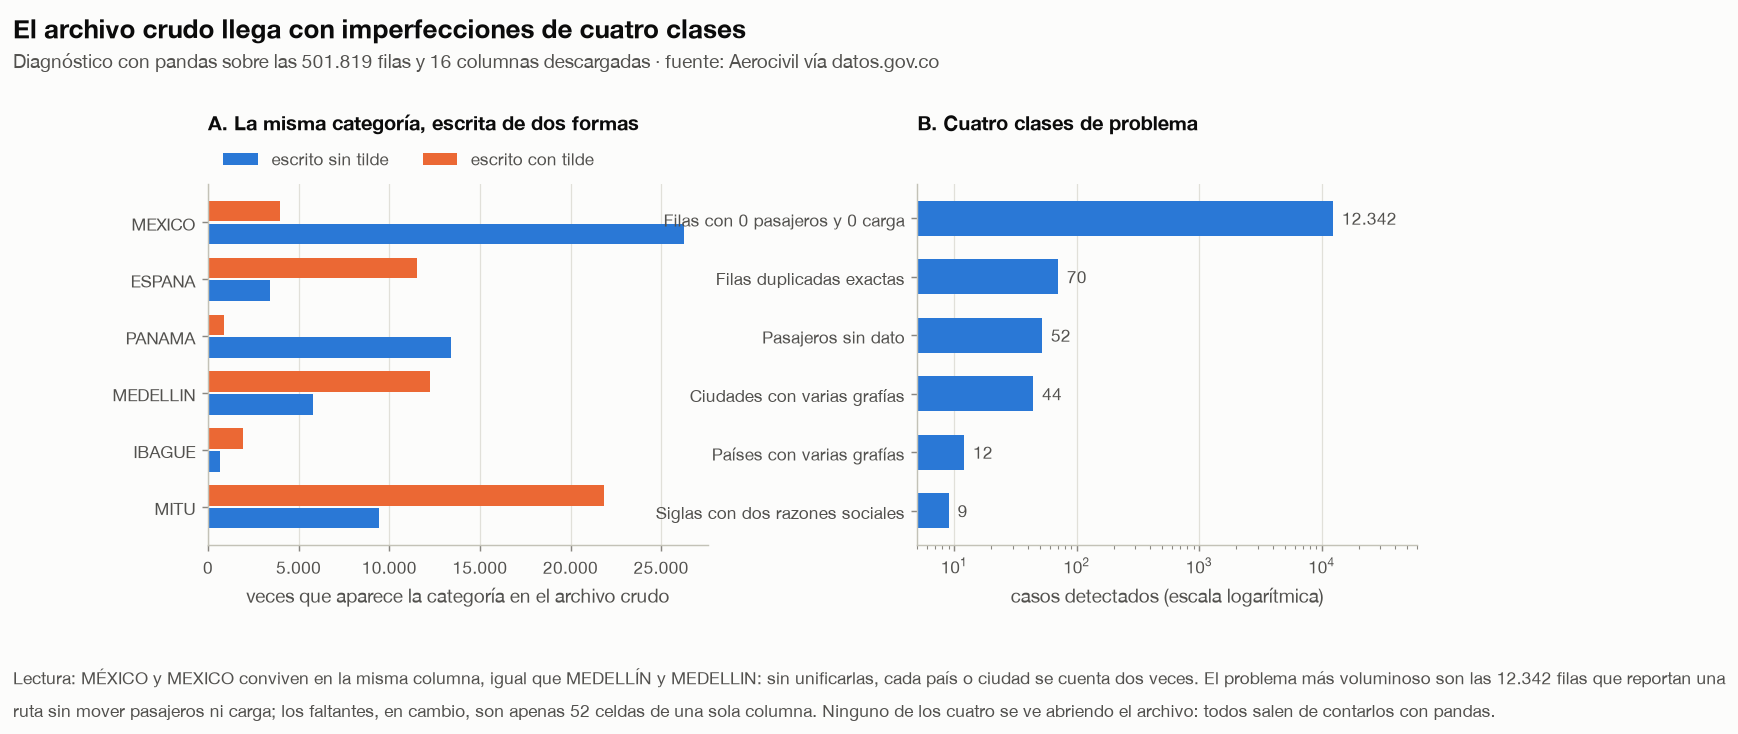

In [8]:
# ===================== FIGURA 0: diagnóstico ================================
pares = [('MEXICO', 'MÉXICO'), ('ESPANA', 'ESPAÑA'), ('PANAMA', 'PANAMÁ'),
         ('MEDELLIN', 'MEDELLÍN'), ('IBAGUE', 'IBAGUÉ'), ('MITU', 'MITÚ')]
conteo = pd.concat([crudo['Pais Origen'], crudo['Pais Destino'],
                    crudo['Ciudad Origen'], crudo['Ciudad Destino']]).value_counts()
sin_t = [conteo.get(a, 0) for a, b in pares]
con_t = [conteo.get(b, 0) for a, b in pares]
y = np.arange(len(pares))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw=dict(wspace=0.42))
a1.barh(y + 0.2, sin_t, height=0.36, color=ev.AZUL, label='escrito sin tilde')
a1.barh(y - 0.2, con_t, height=0.36, color=ev.NARANJA, label='escrito con tilde')
a1.set_yticks(y); a1.set_yticklabels([a for a, b in pares], fontsize=9.5)
a1.invert_yaxis(); a1.grid(axis='y', visible=False)
a1.xaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: ev.miles(v)))
a1.set_xlabel('veces que aparece la categoría en el archivo crudo')
a1.set_title('A. La misma categoría, escrita de dos formas', fontsize=11, pad=30)
a1.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncols=2, fontsize=9.5)

problemas = pd.Series({
    'Filas duplicadas exactas': int(crudo.duplicated().sum()),
    'Pasajeros sin dato': int(crudo['Pasajeros'].isna().sum()),
    'Filas con 0 pasajeros y 0 carga': int(((crudo['Pasajeros'] == 0) & (crudo['Carga_Correo (Kg)'] == 0)).sum()),
    'Ciudades con varias grafías': int(colapsan(ciudades)['normalizado'].nunique()),
    'Países con varias grafías': int(colapsan(paises)['normalizado'].nunique()),
    'Siglas con dos razones sociales': int(len(multiples)),
}).sort_values()
b = a2.barh(problemas.index, problemas.values, color=ev.AZUL, height=0.6)
a2.set_xscale('log'); a2.set_xlim(5, 60000)
a2.bar_label(b, labels=[ev.miles(v) for v in problemas.values], padding=5, fontsize=9.5, color=ev.TINTA_2)
a2.set_xlabel('casos detectados (escala logarítmica)')
a2.set_title('B. Cuatro clases de problema', fontsize=11, pad=30)
a2.tick_params(labelsize=9.5); a2.grid(axis='y', visible=False)
ev.rotular(fig, 'El archivo crudo llega con imperfecciones de cuatro clases',
           'Diagnóstico con pandas sobre las 501.819 filas y 16 columnas descargadas · fuente: Aerocivil vía datos.gov.co',
           'MÉXICO y MEXICO conviven en la misma columna, igual que MEDELLÍN y MEDELLIN: sin unificarlas, cada país '
           'o ciudad se cuenta dos veces. El problema más voluminoso son las 12.342 filas que reportan una ruta sin '
           'mover pasajeros ni carga; los faltantes, en cambio, son apenas 52 celdas de una sola columna. Ninguno de '
           'los cuatro se ve abriendo el archivo: todos salen de contarlos con pandas.',
           top=0.80, bottom=0.17)
ev.guardar(fig, FIG / 'fig00_diagnostico.png')
plt.show()

### Decisiones de limpieza, una por problema

| Problema | Casos | Decisión | Por qué |
|---|---|---|---|
| Nombres de columna con tildes, mayúsculas y espacios | 16 | Renombrar a `snake_case` sin tildes | Evita errores de digitación al escribir código durante todo el análisis. |
| Filas duplicadas exactas | 70 | **Eliminar** | Mismas cifras en las 16 columnas: duplicar el registro inflaría los totales. |
| Clave repetida con cifras distintas | 6 | **Conservar** | Son operaciones distintas del mismo mes; borrarlas eliminaría pasajeros reales. |
| `Pasajeros` faltante con carga > 0 | 41 | **Imputar 0** | Son vuelos que reportaron carga: el cero no es un invento, es la lectura correcta de un vuelo carguero. |
| `Pasajeros` faltante sin carga | 11 | **Eliminar** | La fila no aporta ninguna información: 0,002 % del archivo. |
| Tildes y errores de digitación en categorías | 44 ciudades, 12 países, 9 aerolíneas | **Normalizar** (mayúsculas sin tildes; un nombre por sigla) | Un conteo por categoría solo es correcto si cada categoría es una. |
| `INGLATERRA` / `REINO UNIDO` | 5.413 filas | **Unificar** en `REINO UNIDO` | Es el mismo país con dos nombres, no dos destinos. |
| Filas con 0 pasajeros y 0 carga | 12.340 | **Conservar con bandera** `sin_movimiento` | Informan sobre rutas activas sin operación; se excluyen solo de los estadísticos de magnitud. |
| `Año` y `Mes` separados | todas | **Derivar** `fecha` (`datetime`) | Sin una fecha no hay serie de tiempo posible. |
| Texto libre en variables de pocas categorías | 9 columnas | **Convertir a `category`** | Tipo correcto y menos memoria. |

In [9]:
# ---------------------------------------------------------------- LIMPIEZA
def a_snake(col):
    s = unicodedata.normalize('NFKD', col).encode('ascii', 'ignore').decode()
    return re.sub(r'[^0-9a-zA-Z]+', '_', s).strip('_').lower()

df = crudo.rename(columns={c: a_snake(c) for c in crudo.columns})
df = df.rename(columns={'ano': 'anio', 'numero_de_mes': 'mes',
                        'trafico_n_i': 'tipo_trafico', 'carga_correo_kg': 'carga_kg'})

filas_iniciales = len(df)

# 1) duplicados exactos
df = df.drop_duplicates().reset_index(drop=True)
tras_duplicados = len(df)

# 2) normalizacion de texto
TEXTO = ['nombre', 'sigla_empresa', 'origen', 'nombre_origen', 'ciudad_origen', 'pais_origen',
         'destino', 'nombre_destino', 'ciudad_destino', 'pais_destino']
for c in TEXTO:
    df[c] = df[c].map(sin_tildes)
df['pais_origen'] = df['pais_origen'].replace({'INGLATERRA': 'REINO UNIDO'})
df['pais_destino'] = df['pais_destino'].replace({'INGLATERRA': 'REINO UNIDO'})

# un solo nombre por sigla de aerolinea: el mas frecuente
nombre_modal = df.groupby('sigla_empresa')['nombre'].agg(lambda s: s.value_counts().idxmax())
df['empresa'] = df['sigla_empresa'].map(nombre_modal)

# 3) faltantes de pasajeros
na = df.pasajeros.isna()
imputadas = int((na & (df.carga_kg > 0)).sum())
df.loc[na & (df.carga_kg > 0), 'pasajeros'] = 0
eliminadas = int(df.pasajeros.isna().sum())
df = df[df.pasajeros.notna()].copy()
df['pasajeros'] = df['pasajeros'].astype('int64')

# 4) tipos correctos y variables derivadas
df['fecha'] = pd.to_datetime(dict(year=df.anio, month=df.mes, day=1))
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
df['mes_nombre'] = pd.Categorical(df.mes.map(lambda m: MESES[m - 1]), categories=MESES, ordered=True)
df['tipo_trafico'] = pd.Categorical(
    df.tipo_trafico.map({'N': 'Nacional', 'I': 'Internacional', 'E': 'Entre terceros paises'}),
    categories=['Nacional', 'Internacional', 'Entre terceros paises'])
df['tipo_vuelo'] = pd.Categorical(
    df.tipo_vuelo.map({'R': 'Regular', 'T': 'Taxi aereo', 'C': 'Charter', 'A': 'Adicional'}),
    categories=['Regular', 'Taxi aereo', 'Charter', 'Adicional'])
df['carga_t'] = df.carga_kg / 1000.0
df['ruta'] = df.origen + '-' + df.destino
df['sin_movimiento'] = (df.pasajeros == 0) & (df.carga_kg == 0)
df['solo_carga'] = (df.pasajeros == 0) & (df.carga_kg > 0)
for c in ['sigla_empresa', 'empresa', 'origen', 'destino', 'ciudad_origen', 'ciudad_destino',
          'pais_origen', 'pais_destino', 'ruta']:
    df[c] = df[c].astype('category')

(BASE / 'datos' / 'procesados').mkdir(parents=True, exist_ok=True)
df.to_parquet(BASE / 'datos' / 'procesados' / 'trafico_aereo_limpio.parquet', index=False)

print(f'Filas antes de limpiar      : {filas_iniciales:,}'.replace(',', '.'))
print(f'  - duplicados exactos      : -{filas_iniciales - tras_duplicados}')
print(f'  - faltantes imputados a 0 : {imputadas} (vuelos con carga y sin pasajeros)')
print(f'  - filas vacías eliminadas : -{eliminadas}')
print(f'Filas después de limpiar    : {len(df):,}'.replace(',', '.'))
print(f'Columnas: {crudo.shape[1]} -> {df.shape[1]} (se derivaron 7 variables nuevas)')
print()
print('Categorías únicas antes y después de normalizar:')
print(f"  países   : {paises.nunique()} -> {pd.concat([df.pais_origen.astype(str), df.pais_destino.astype(str)]).nunique()}")
print(f"  ciudades : {ciudades.nunique()} -> {pd.concat([df.ciudad_origen.astype(str), df.ciudad_destino.astype(str)]).nunique()}")
print(f"  empresas : {crudo['Nombre'].nunique()} -> {df.empresa.nunique()}")

Filas antes de limpiar      : 501.819
  - duplicados exactos      : -70
  - faltantes imputados a 0 : 41 (vuelos con carga y sin pasajeros)
  - filas vacías eliminadas : -11
Filas después de limpiar    : 501.738
Columnas: 16 -> 23 (se derivaron 7 variables nuevas)

Categorías únicas antes y después de normalizar:
  países   : 167 -> 155


  ciudades : 900 -> 856
  empresas : 174 -> 165


In [10]:
df.dtypes.to_frame('tipo tras la limpieza')

,tipo tras la limpieza
sigla_empresa,category
nombre,str
anio,int64
mes,int64
origen,category
nombre_origen,str
ciudad_origen,category
pais_origen,category
destino,category
nombre_destino,str


## 4. Resumen univariado

Con el conjunto limpio (501.738 filas × 23 columnas) se describe cada variable con los estadísticos que
corresponden a su tipo. Los **registros activos** son los que movieron algo: pasajeros o carga.

In [11]:
act = df[~df.sin_movimiento]                      # registros con movimiento real
print('Registros totales :', f'{len(df):,}'.replace(',', '.'))
print('Registros activos :', f'{len(act):,}'.replace(',', '.'),
      f'({100*len(act)/len(df):.1f} %)')
MES_ES = ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 'julio',
          'agosto', 'septiembre', 'octubre', 'noviembre', 'diciembre']
def en_espanol(ts):
    return f'{MES_ES[ts.month-1]} de {ts.year}'
print('Período           :', en_espanol(df.fecha.min()), '→', en_espanol(df.fecha.max()))
print('Rutas distintas   :', df.ruta.nunique(), '| aerolíneas:', df.empresa.nunique(),
      '| aeropuertos:', df.origen.nunique(), '| países:',
      pd.concat([df.pais_origen.astype(str), df.pais_destino.astype(str)]).nunique())

resumen_num = act[['pasajeros', 'carga_t']].describe(percentiles=[.25, .5, .75, .9, .95, .99]).T
resumen_num['asimetría'] = [act.pasajeros.skew(), act.carga_t.skew()]
resumen_num['curtosis'] = [act.pasajeros.kurtosis(), act.carga_t.kurtosis()]
resumen_num.round(2)

Registros totales : 501.738
Registros activos : 489.398 (97.5 %)
Período           : enero de 2020 → septiembre de 2026
Rutas distintas   : 14133 | aerolíneas: 165 | aeropuertos: 1277 | países: 155


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max,asimetría,curtosis
pasajeros,489398.0,613.74,2975.58,0.0,4.0,18.0,108.0,797.00,2968.0,12649.03,80532.00,10.83,159.59
carga_t,489398.0,13.39,143.50,0.0,0.0,0.0,0.1,2.74,18.5,305.25,11343.04,31.54,1409.47


In [12]:
# Variables categoricas: frecuencias
for col in ['tipo_trafico', 'tipo_vuelo']:
    t = act[col].value_counts()
    t = pd.DataFrame({'registros': t, '% registros': (100*t/t.sum()).round(1),
                      '% pasajeros': (100*act.groupby(col, observed=True).pasajeros.sum()/act.pasajeros.sum()).round(1)})
    print(f'--- {col}')
    print(t.to_string(), '\n')

print('--- las 5 aerolíneas con más pasajeros (todo el período)')
print((act.groupby('empresa', observed=True).pasajeros.sum().sort_values(ascending=False).head(5) / 1e6)
      .round(2).to_frame('millones de pasajeros').to_string())

--- tipo_trafico


                       registros  % registros  % pasajeros
tipo_trafico                                              
Nacional                  153261         31.3         61.7
Internacional             324036         66.2         38.0
Entre terceros paises      12101          2.5          0.4 

--- tipo_vuelo
            registros  % registros  % pasajeros
tipo_vuelo                                     
Regular        385547         78.8         98.4
Taxi aereo      86930         17.8          0.6
Charter         10702          2.2          0.8
Adicional        6219          1.3          0.3 

--- las 5 aerolíneas con más pasajeros (todo el período)
                   millones de pasajeros
empresa                                 
AVIANCA                           111.22
AIRES                              53.70
AEROREPUBLICA                      17.09
FAST COLOMBIA SAS                  15.47
COPA AIRLINES                      13.45


**Forma de las distribuciones numéricas.** `pasajeros` tiene centro bajo (mediana 18, media 614), dispersión
enorme (desviación 2.976) y una asimetría de 10,8 con curtosis de 160: una cola derecha larguísima. `carga_t`
es todavía más extrema. En los dos casos **la media no describe nada**: hay dos poblaciones mezcladas en el
mismo archivo, y la figura 1 lo muestra.

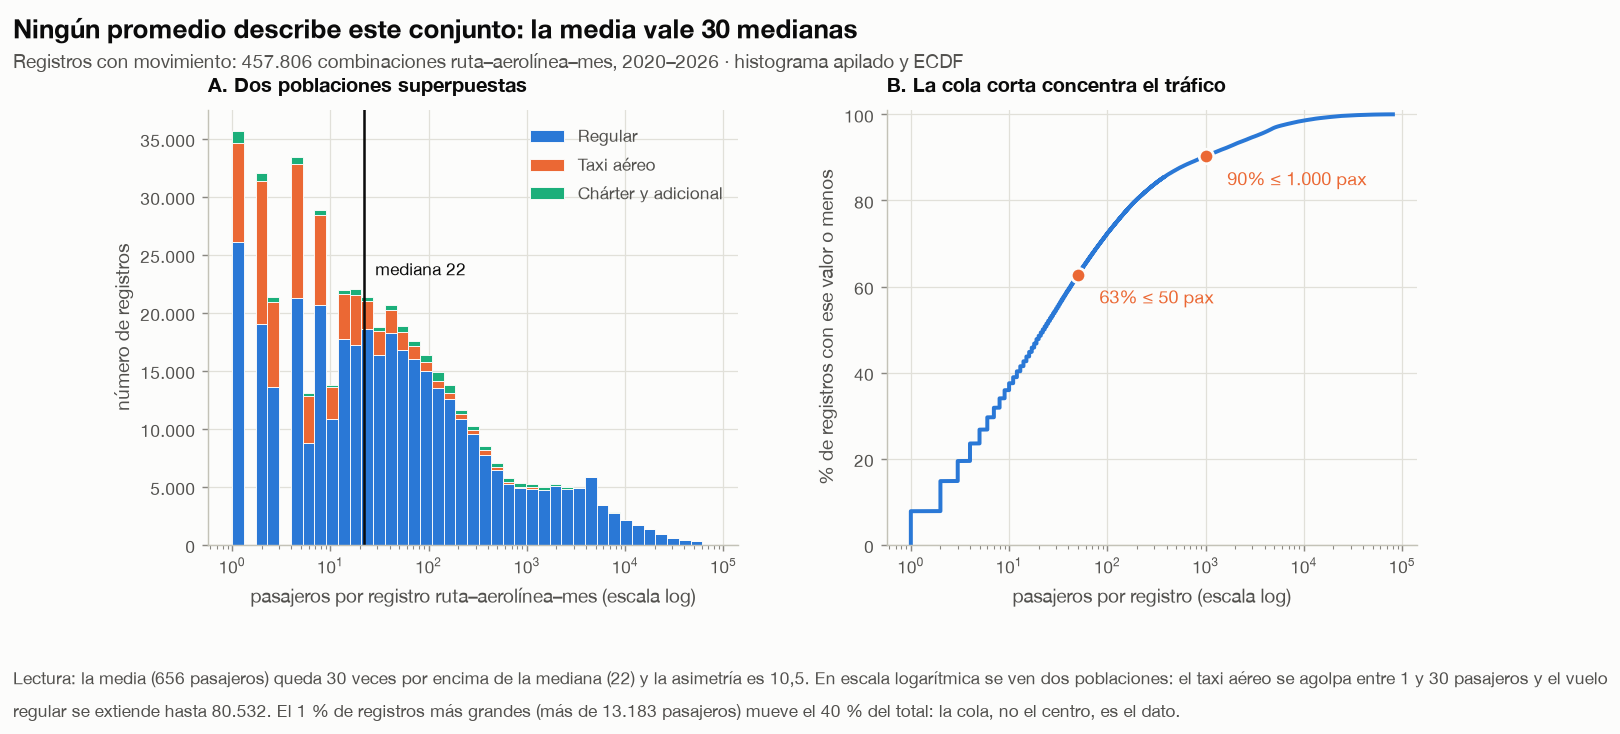

In [13]:
# ============================ FIGURA 1: distribución =========================
x = act.loc[act.pasajeros > 0, 'pasajeros']
grupos = [('Regular', ev.AZUL), ('Taxi aéreo', ev.NARANJA), ('Chárter y adicional', ev.AQUA)]
mapa = {'Regular': 'Regular', 'Taxi aereo': 'Taxi aéreo',
        'Charter': 'Chárter y adicional', 'Adicional': 'Chárter y adicional'}
d = act[act.pasajeros > 0].copy()
d['grupo'] = d.tipo_vuelo.astype(str).map(mapa)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw=dict(wspace=0.28))
bins = np.logspace(0, np.log10(x.max()), 42)
a1.hist([d.loc[d.grupo == g, 'pasajeros'] for g, _ in grupos], bins=bins, stacked=True,
        color=[c for _, c in grupos], label=[g for g, _ in grupos],
        edgecolor=ev.SUPERFICIE, linewidth=0.5)
a1.set_xscale('log')
a1.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: ev.miles(v)))
a1.set_xlabel('pasajeros por registro ruta–aerolínea–mes (escala log)')
a1.set_ylabel('número de registros')
a1.set_title('A. Dos poblaciones superpuestas', fontsize=11)
a1.legend(loc='upper right')
a1.axvline(x.median(), color=ev.TINTA, linewidth=1.4)
a1.text(x.median()*1.3, a1.get_ylim()[1]*0.62, f'mediana {int(x.median())}', color=ev.TINTA, fontsize=9.5)

xs = np.sort(x.values); ys = np.arange(1, len(xs)+1)/len(xs)*100
a2.plot(xs, ys, color=ev.AZUL, linewidth=2.2)
a2.set_xscale('log'); a2.set_ylim(0, 101)
a2.set_xlabel('pasajeros por registro (escala log)')
a2.set_ylabel('% de registros con ese valor o menos')
a2.set_title('B. La cola corta concentra el tráfico', fontsize=11)
for umbral in (50, 1000):
    p = (x <= umbral).mean()*100
    a2.plot([umbral], [p], 'o', color=ev.NARANJA, markersize=8, zorder=5,
            markeredgecolor=ev.SUPERFICIE, markeredgewidth=1.5)
    a2.annotate(f'{p:.0f}% ≤ {ev.miles(umbral)} pax', (umbral, p), textcoords='offset points',
                xytext=(12, -16), fontsize=10, color=ev.NARANJA)

p99 = x.quantile(.99)
ev.rotular(fig, 'Ningún promedio describe este conjunto: la media vale 30 medianas',
           f'Registros con movimiento: {ev.miles(len(x))} combinaciones ruta–aerolínea–mes, 2020–2026 · histograma apilado y ECDF',
           f'la media ({int(x.mean())} pasajeros) queda 30 veces por encima de la mediana ({int(x.median())}) y la '
           f'asimetría es {ev.num(x.skew(),1)}. En escala logarítmica se ven dos poblaciones: el taxi aéreo se agolpa '
           f'entre 1 y 30 pasajeros y el vuelo regular se extiende hasta {ev.miles(x.max())}. El 1 % de registros más '
           f'grandes (más de {ev.miles(p99)} pasajeros) mueve el 40 % del total: la cola, no el centro, es el dato.',
           top=0.93, bottom=0.17)
ev.guardar(fig, FIG / 'fig01_distribucion.png')
plt.show()

**Por qué un histograma en escala logarítmica y una ECDF.** La pregunta es por la *forma* de la distribución,
y el histograma es la herramienta directa; pero en escala lineal los 489 mil registros se aplastarían contra el
eje izquierdo y la figura solo mostraría una barra. La escala logarítmica separa los órdenes de magnitud y deja
ver las dos poblaciones. La ECDF del panel B responde una pregunta distinta —qué proporción queda bajo un
umbral— sin depender del ancho del bin, que es la debilidad del histograma.

In [14]:
# Valores atípicos: regla del rango intercuartílico sobre pasajeros
q1, q3 = act.pasajeros.quantile([.25, .75])
iqr = q3 - q1
limite = q3 + 1.5*iqr
atipicos = act[act.pasajeros > limite]
print(f'Límite superior de la regla IQR: {limite:.0f} pasajeros')
print(f'Registros por encima del límite: {len(atipicos):,}'.replace(',', '.'),
      f'({100*len(atipicos)/len(act):.1f} % de los registros activos)')
print(f'Esos registros concentran el {100*atipicos.pasajeros.sum()/act.pasajeros.sum():.1f} % de los pasajeros')
print()
print('Los 5 registros más grandes del conjunto:')
print(act.nlargest(5, 'pasajeros')[['empresa', 'anio', 'mes', 'origen', 'destino',
                                    'tipo_vuelo', 'pasajeros']].to_string(index=False))
print()
print('Los 3 registros con más carga:')
print(act.nlargest(3, 'carga_t')[['empresa', 'anio', 'mes', 'origen', 'destino',
                                  'pasajeros', 'carga_t']].round(0).to_string(index=False))

Límite superior de la regla IQR: 264 pasajeros
Registros por encima del límite: 79.172 (16.2 % de los registros activos)
Esos registros concentran el 95.2 % de los pasajeros

Los 5 registros más grandes del conjunto:
empresa  anio  mes origen destino tipo_vuelo  pasajeros
AVIANCA  2024    8    MDE     BOG    Regular      80532
AVIANCA  2020    1    MDE     BOG    Regular      79817
  AIRES  2023   12    BOG     MDE    Regular      79763
AVIANCA  2024    9    MDE     BOG    Regular      79202
AVIANCA  2024    5    MDE     BOG    Regular      78627

Los 3 registros con más carga:
          empresa  anio  mes origen destino  pasajeros  carga_t
TAMPA CARGO S.A.S  2022    4    BOG     MIA          0  11343.0
TAMPA CARGO S.A.S  2023    1    BOG     MIA          0  10314.0
TAMPA CARGO S.A.S  2022    5    BOG     MIA          0   9493.0


**Qué se hace con los atípicos: conservarlos.** La regla del rango intercuartílico marca 79.172 registros
(16 % del total) como atípicos, lo cual ya es una señal de que la regla **no aplica** aquí: fue diseñada para
distribuciones aproximadamente simétricas. Al revisar los casos extremos uno por uno se ve que son operaciones
reales y verificables: el máximo (80.532 pasajeros de Avianca entre Rionegro y Bogotá en agosto de 2024) es el
puente aéreo Medellín–Bogotá, la ruta más transitada del país; los máximos de carga son vuelos de Tampa Cargo
entre Bogotá y Miami, el corredor de carga más importante de Colombia.

**No son errores, son el fenómeno.** Eliminarlos borraría justamente lo que explica el sistema. La decisión es
conservarlos y adaptar las herramientas: escalas logarítmicas, medianas en vez de medias y correlación de
Spearman en vez de Pearson.

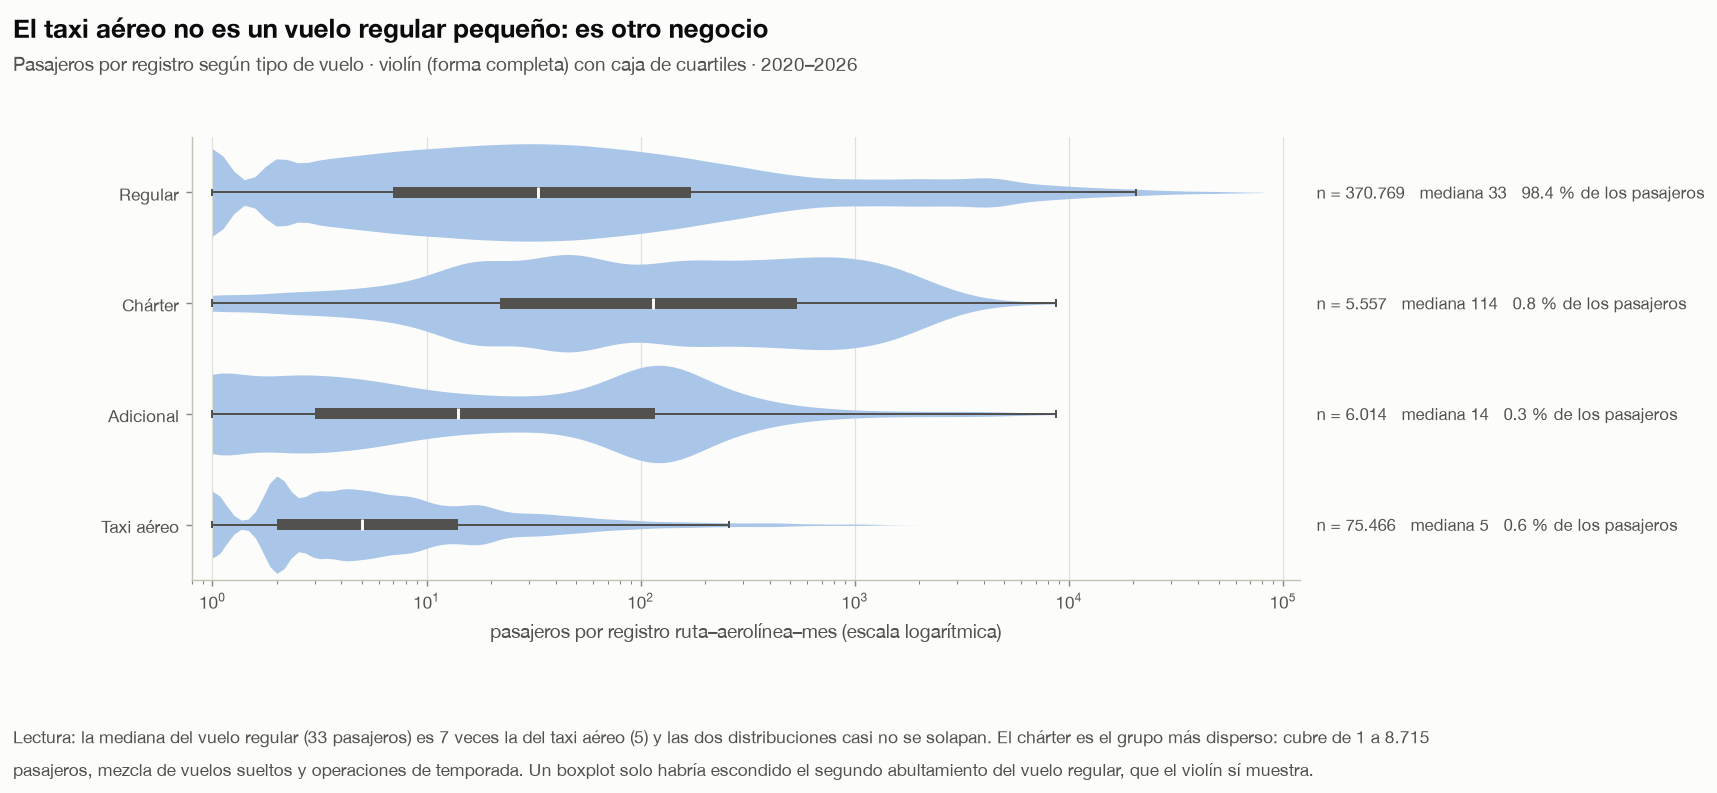

In [15]:
# ===================== FIGURA 2: comparación entre grupos ====================
orden = ['Regular', 'Charter', 'Adicional', 'Taxi aereo']
etiq = {'Regular': 'Regular', 'Charter': 'Chárter', 'Adicional': 'Adicional', 'Taxi aereo': 'Taxi aéreo'}
dv = act[act.pasajeros > 0].copy()
dv['tipo_vuelo'] = dv.tipo_vuelo.astype(str)

fig, ax = plt.subplots(figsize=(11, 4.8))
sns.violinplot(data=dv, y='tipo_vuelo', x='pasajeros', order=orden, ax=ax, log_scale=True,
               density_norm='width', cut=0, inner=None, color=ev.AZULES[2], linewidth=0, width=0.88)
sns.boxplot(data=dv, y='tipo_vuelo', x='pasajeros', order=orden, ax=ax, log_scale=True, width=0.1,
            showfliers=False, boxprops=dict(facecolor=ev.TINTA_2, edgecolor='none'),
            medianprops=dict(color=ev.SUPERFICIE, linewidth=1.6),
            whiskerprops=dict(color=ev.TINTA_2, linewidth=1.1),
            capprops=dict(color=ev.TINTA_2, linewidth=1.1))
ax.set_yticks(range(len(orden))); ax.set_yticklabels([etiq[o] for o in orden])
ax.set_xlabel('pasajeros por registro ruta–aerolínea–mes (escala logarítmica)')
ax.set_ylabel(''); ax.grid(axis='y', visible=False); ax.set_xlim(0.8, 1.2e5)
for i, o in enumerate(orden):
    s = dv.loc[dv.tipo_vuelo == o, 'pasajeros']
    ax.text(1.015, i, f'n = {ev.miles(len(s))}   mediana {int(s.median())}   '
                      f'{100*s.sum()/dv.pasajeros.sum():.1f} % de los pasajeros',
            transform=ax.get_yaxis_transform(), va='center', fontsize=9.2, color=ev.TINTA_2)

reg = dv.loc[dv.tipo_vuelo == 'Regular', 'pasajeros']
tax = dv.loc[dv.tipo_vuelo == 'Taxi aereo', 'pasajeros']
ev.rotular(fig, 'El taxi aéreo no es un vuelo regular pequeño: es otro negocio',
           'Pasajeros por registro según tipo de vuelo · violín (forma completa) con caja de cuartiles · 2020–2026',
           f'la mediana del vuelo regular ({int(reg.median())} pasajeros) es {reg.median()/tax.median():.0f} veces la '
           f'del taxi aéreo ({int(tax.median())}) y las dos distribuciones casi no se solapan. El chárter es el grupo '
           f'más disperso: cubre de 1 a {ev.miles(dv.loc[dv.tipo_vuelo=="Charter","pasajeros"].max())} pasajeros, '
           f'mezcla de vuelos sueltos y operaciones de temporada. Un boxplot solo habría escondido el segundo '
           f'abultamiento del vuelo regular, que el violín sí muestra.',
           top=0.90, bottom=0.19)
ev.guardar(fig, FIG / 'fig02_grupos.png')
plt.show()

**Por qué violín y no solo boxplot.** La pregunta es si los cuatro tipos de vuelo son el mismo fenómeno a
distinta escala. Un boxplot comparte los cuartiles, que es lo mínimo, pero oculta la forma: no habría mostrado
que el vuelo regular tiene dos abultamientos ni que el chárter es casi plano a lo largo de tres órdenes de
magnitud. El violín recupera la forma y la caja conserva la referencia de los cuartiles; se dibujan juntos
porque responden partes distintas de la misma pregunta.

## 5. Relaciones entre variables

Tres relaciones, una de cada tipo: dos numéricas entre sí, una numérica comparada entre grupos y dos
categóricas entre sí.

In [16]:
# 5.1 Correlación entre las variables numéricas, agregando por ruta y mes
rm = (act.groupby(['ruta', 'fecha'], observed=True)
         .agg(pasajeros=('pasajeros', 'sum'), carga_t=('carga_t', 'sum'),
              aerolineas=('sigla_empresa', 'nunique'), registros=('pasajeros', 'size'))
         .reset_index())
rm['pax_por_aerolinea'] = rm.pasajeros / rm.aerolineas
cols = ['pasajeros', 'carga_t', 'aerolineas', 'registros', 'pax_por_aerolinea']

print('n ruta-mes:', f'{len(rm):,}'.replace(',', '.'))
print('\nPearson (sensible a los valores extremos):')
print(rm[cols].corr().round(2).to_string())
print('\nSpearman (sobre rangos, robusta a la asimetría):')
print(rm[cols].corr(method='spearman').round(2).to_string())

n ruta-mes: 271.416

Pearson (sensible a los valores extremos):
                   pasajeros  carga_t  aerolineas  registros  pax_por_aerolinea
pasajeros               1.00     0.20        0.47       0.49               0.85
carga_t                 0.20     1.00        0.36       0.38               0.10
aerolineas              0.47     0.36        1.00       0.99               0.36
registros               0.49     0.38        0.99       1.00               0.38
pax_por_aerolinea       0.85     0.10        0.36       0.38               1.00

Spearman (sobre rangos, robusta a la asimetría):
                   pasajeros  carga_t  aerolineas  registros  pax_por_aerolinea
pasajeros               1.00     0.24        0.58       0.59               0.98
carga_t                 0.24     1.00        0.39       0.38               0.20
aerolineas              0.58     0.39        1.00       0.99               0.43
registros               0.59     0.38        0.99       1.00               0.45
pax_po

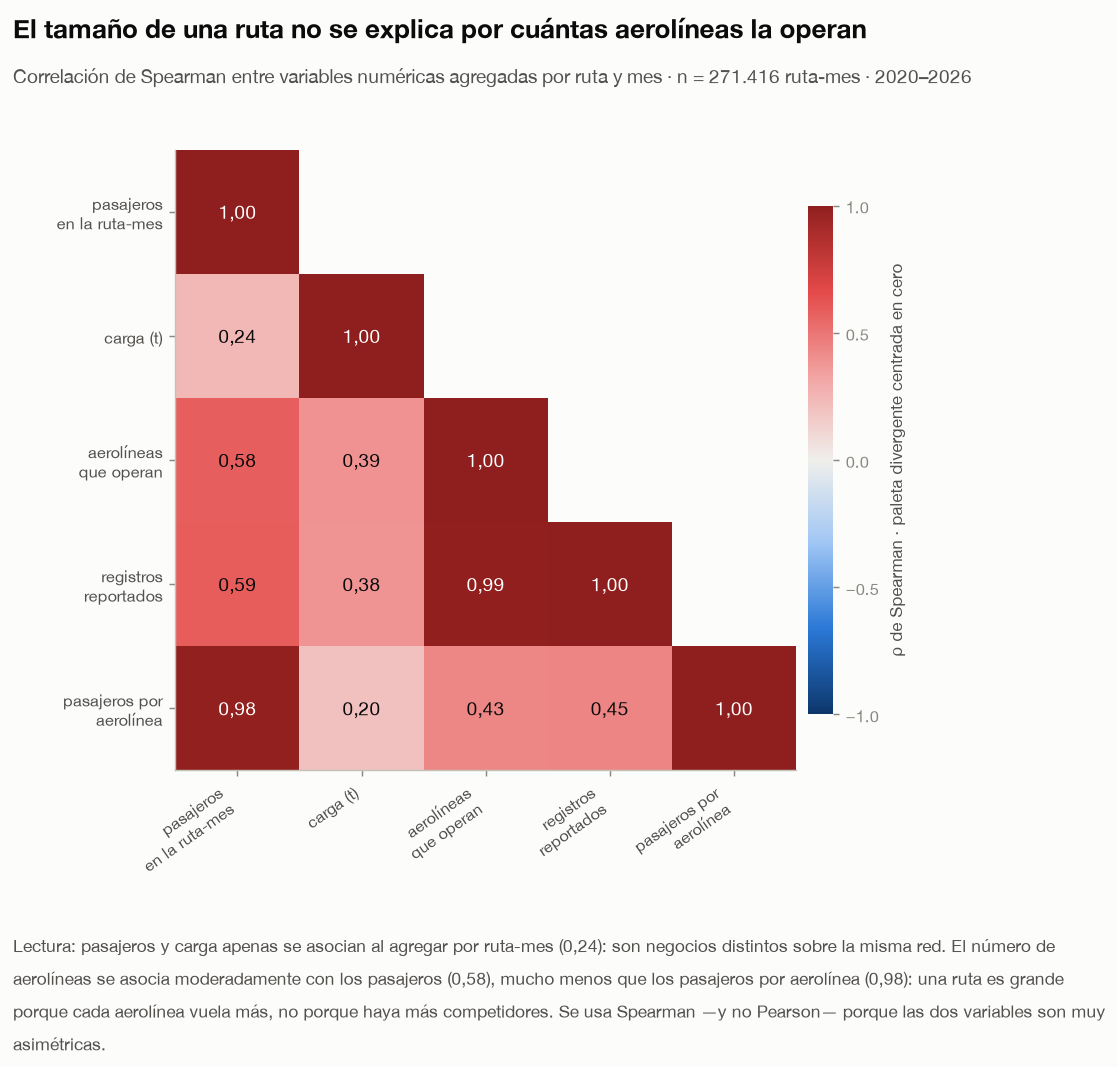

In [17]:
# ======================== FIGURA 3: correlaciones ===========================
C = rm[cols].corr(method='spearman')
etq = ['pasajeros\nen la ruta-mes', 'carga (t)', 'aerolíneas\nque operan',
       'registros\nreportados', 'pasajeros por\naerolínea']
mascara = np.triu(np.ones_like(C.values, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7.8, 6.2))
M = np.ma.masked_where(mascara, C.values)
im = ax.imshow(M, cmap=ev.DIVERGENTE, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(etq, rotation=35, ha='right', fontsize=9)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(etq, fontsize=9); ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        if not mascara[i, j]:
            v = C.values[i, j]
            ax.text(j, i, ev.num(v, 2), ha='center', va='center', fontsize=10.5,
                    color='white' if abs(v) > 0.72 else ev.TINTA)
cb = fig.colorbar(im, ax=ax, pad=0.015, ticks=[-1, -0.5, 0, 0.5, 1], shrink=0.82)
cb.set_label('ρ de Spearman · paleta divergente centrada en cero', fontsize=9.3, color=ev.TINTA_2)
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=9, colors=ev.TINTA_3)
ev.rotular(fig, 'El tamaño de una ruta no se explica por cuántas aerolíneas la operan',
           f'Correlación de Spearman entre variables numéricas agregadas por ruta y mes · n = {ev.miles(len(rm))} ruta-mes · 2020–2026',
           'pasajeros y carga apenas se asocian al agregar por ruta-mes (0,24): son negocios distintos sobre la '
           'misma red. El número de aerolíneas se asocia moderadamente con los pasajeros (0,58), mucho menos que los '
           'pasajeros por aerolínea (0,98): una ruta es grande porque cada aerolínea vuela más, no porque haya más '
           'competidores. Se usa Spearman —y no Pearson— porque las dos variables son muy asimétricas.',
           top=0.93, bottom=0.16)
ev.guardar(fig, FIG / 'fig03_correlacion.png')
plt.show()

**Por qué un heatmap y por qué Spearman.** Una matriz de correlaciones es una matriz: el heatmap muestra las
diez relaciones de un vistazo y la paleta divergente centrada en cero permite leer el signo sin consultar la
leyenda. Se dibuja solo el triángulo inferior porque la matriz es simétrica y repetirla duplica la tinta sin
añadir información. La correlación se calcula sobre rangos (Spearman) porque Pearson quedaría dominada por el
puñado de rutas gigantes: en los datos en nivel, Pearson entre pasajeros y carga da 0,48 y Spearman 0,76; la
diferencia la producen los extremos, no la relación típica.

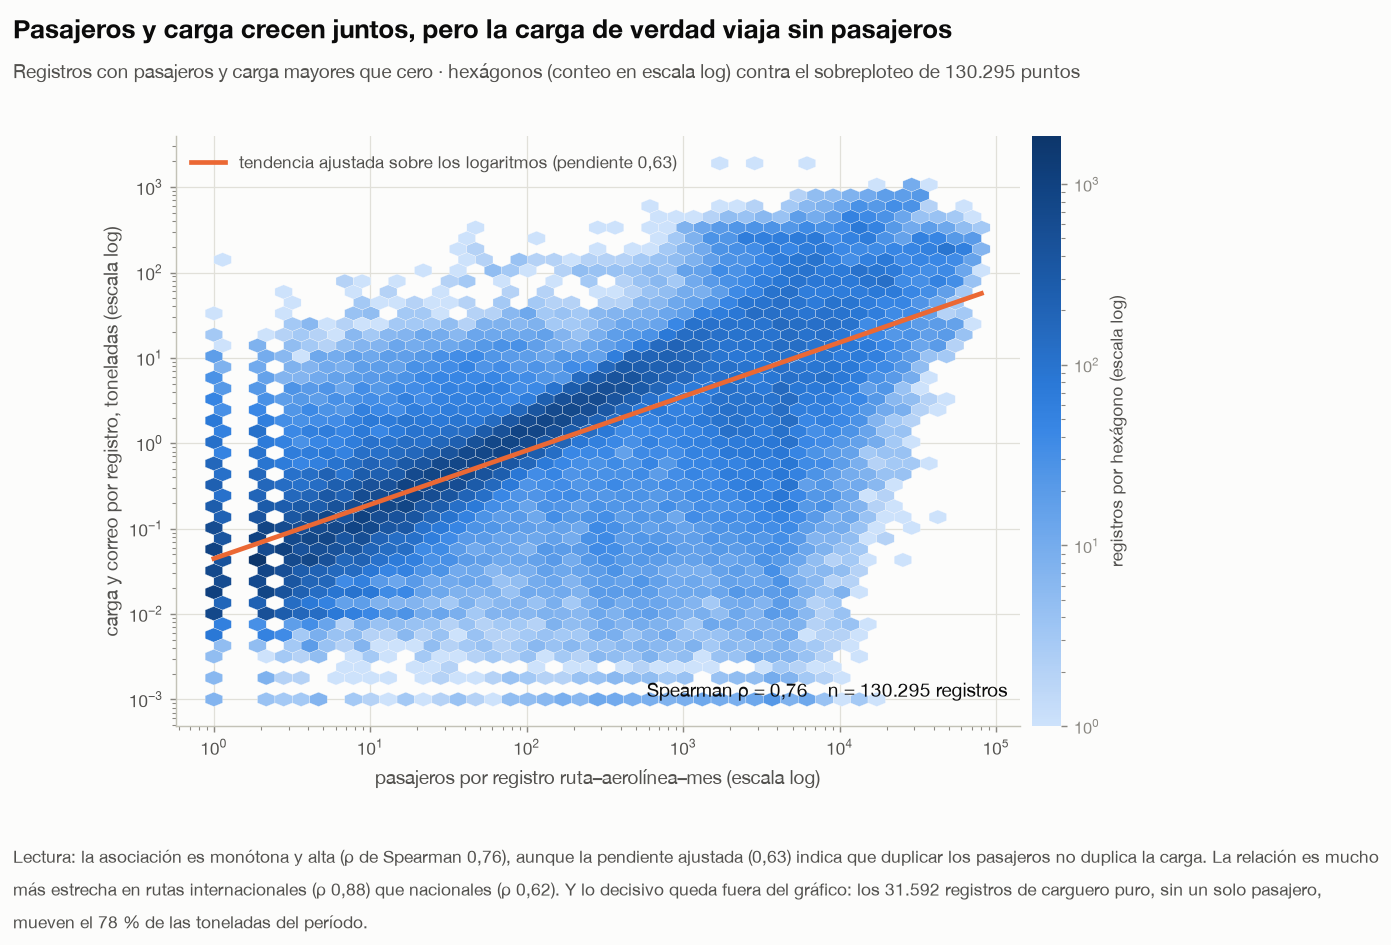

Toneladas movidas por vuelos sin pasajeros: 78 % del total


In [18]:
# ================= FIGURA 4: relación entre dos numéricas ===================
amb = act[(act.pasajeros > 0) & (act.carga_t > 0)]
rho = amb.pasajeros.corr(amb.carga_t, method='spearman')
rho_n = amb[amb.tipo_trafico == 'Nacional'].pasajeros.corr(
        amb[amb.tipo_trafico == 'Nacional'].carga_t, method='spearman')
rho_i = amb[amb.tipo_trafico == 'Internacional'].pasajeros.corr(
        amb[amb.tipo_trafico == 'Internacional'].carga_t, method='spearman')

fig, ax = plt.subplots(figsize=(10, 5.6))
hb = ax.hexbin(amb.pasajeros, amb.carga_t, xscale='log', yscale='log', gridsize=44,
               cmap=ev.SECUENCIAL, mincnt=1, bins='log', linewidths=0.15, edgecolors=ev.SUPERFICIE)
b, a = np.polyfit(np.log10(amb.pasajeros), np.log10(amb.carga_t), 1)
xx = np.logspace(0, np.log10(amb.pasajeros.max()), 50)
ax.plot(xx, 10**(a + b*np.log10(xx)), color=ev.NARANJA, linewidth=2.6,
        label=f'tendencia ajustada sobre los logaritmos (pendiente {ev.num(b, 2)})')
ax.set_xlabel('pasajeros por registro ruta–aerolínea–mes (escala log)')
ax.set_ylabel('carga y correo por registro, toneladas (escala log)')
ax.legend(loc='upper left')
cb = fig.colorbar(hb, ax=ax, pad=0.012)
cb.set_label('registros por hexágono (escala log)', fontsize=9.5, color=ev.TINTA_2)
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=9, colors=ev.TINTA_3)
ax.text(0.985, 0.05, f'Spearman ρ = {ev.num(rho, 2)}    n = {ev.miles(len(amb))} registros',
        transform=ax.transAxes, ha='right', fontsize=10.5, color=ev.TINTA)
ev.rotular(fig, 'Pasajeros y carga crecen juntos, pero la carga de verdad viaja sin pasajeros',
           'Registros con pasajeros y carga mayores que cero · hexágonos (conteo en escala log) contra el sobreploteo de 130.295 puntos',
           f'la asociación es monótona y alta (ρ de Spearman {ev.num(rho, 2)}), aunque la pendiente ajustada '
           f'({ev.num(b, 2)}) indica que duplicar los pasajeros no duplica la carga. La relación es mucho más '
           f'estrecha en rutas internacionales (ρ {ev.num(rho_i, 2)}) que nacionales (ρ {ev.num(rho_n, 2)}). Y lo '
           f'decisivo queda fuera del gráfico: los {ev.miles(act.solo_carga.sum())} registros de carguero puro, sin '
           f'un solo pasajero, mueven el 78 % de las toneladas del período.',
           top=0.93, bottom=0.12)
ev.guardar(fig, FIG / 'fig04_pasajeros_carga.png')
plt.show()

print('Toneladas movidas por vuelos sin pasajeros: '
      f'{100*act.loc[act.solo_carga, "carga_t"].sum()/act.carga_t.sum():.0f} % del total')

**Por qué hexágonos y no una dispersión.** Son 130.295 puntos: una dispersión simple se convierte en una
mancha donde no se distingue si una zona tiene cien o diez mil registros. El hexbin cuenta registros por celda
y resuelve el sobreploteo; el conteo se colorea en escala logarítmica porque la celda más densa tiene 1.500
veces más registros que las del borde y, en escala lineal, todo el gráfico quedaría del color más claro.
La línea de tendencia se ajusta sobre los logaritmos: en una relación de este tipo, una recta en escala lineal
estaría definida únicamente por los extremos.

Tabla de contingencia (registros activos):
tipo_trafico  Nacional  Internacional  Entre terceros paises
tipo_vuelo                                                  
Regular          60694         314823                  10030
Charter           5407           4363                    932
Adicional         3701           2296                    222
Taxi aereo       83459           2554                    917

χ² = 219.620 | gl = 6 | p = 0 | V de Cramér = 0.474


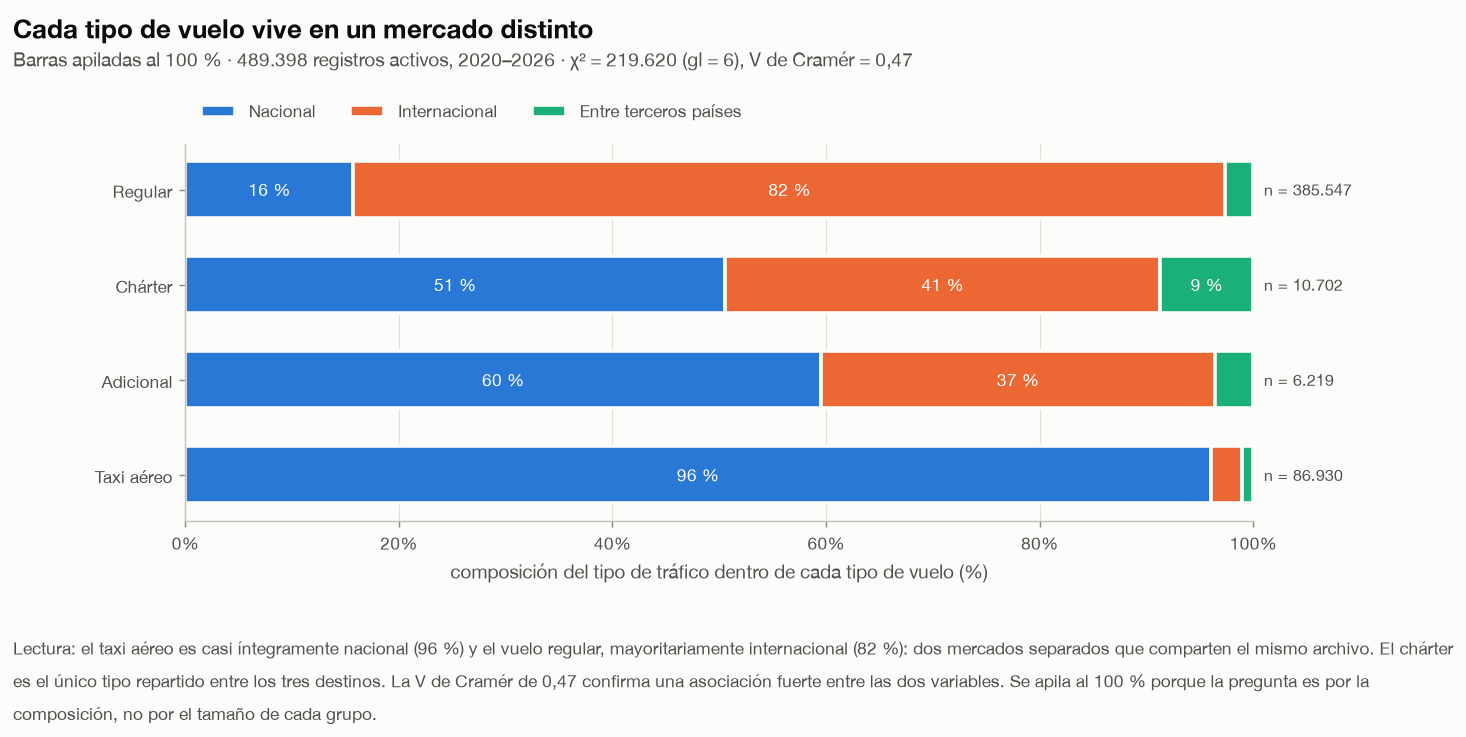

In [19]:
# ========= FIGURA 5: asociación entre dos variables categóricas =============
tab = pd.crosstab(act.tipo_vuelo, act.tipo_trafico).loc[['Regular', 'Charter', 'Adicional', 'Taxi aereo']]
pct = 100 * tab.div(tab.sum(axis=1), axis=0)
chi2, p, dof, esperadas = stats.chi2_contingency(tab)
V = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
print('Tabla de contingencia (registros activos):'); print(tab.to_string())
print(f'\nχ² = {chi2:,.0f}'.replace(',', '.'), f'| gl = {dof} | p = {p:.3g} | V de Cramér = {V:.3f}')

etiq = {'Regular': 'Regular', 'Charter': 'Chárter', 'Adicional': 'Adicional', 'Taxi aereo': 'Taxi aéreo'}
cols_c = {'Nacional': ev.AZUL, 'Internacional': ev.NARANJA, 'Entre terceros paises': ev.AQUA}
nom = {'Nacional': 'Nacional', 'Internacional': 'Internacional',
       'Entre terceros paises': 'Entre terceros países'}

fig, ax = plt.subplots(figsize=(10.6, 4.2))
izq = np.zeros(len(pct)); ypos = np.arange(len(pct))
for c in ['Nacional', 'Internacional', 'Entre terceros paises']:
    v = pct[c].values
    ax.barh(ypos, v, left=izq, height=0.6, color=cols_c[c], label=nom[c],
            edgecolor=ev.SUPERFICIE, linewidth=2)
    for i, (vi, li) in enumerate(zip(v, izq)):
        if vi >= 6:
            ax.text(li + vi/2, i, f'{vi:.0f} %', ha='center', va='center', fontsize=9.5, color='white')
    izq = izq + v
ax.set_yticks(ypos); ax.set_yticklabels([etiq[i] for i in pct.index]); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(mt.PercentFormatter())
ax.set_xlabel('composición del tipo de tráfico dentro de cada tipo de vuelo (%)')
for i, idx in enumerate(pct.index):
    ax.text(101, i, f'n = {ev.miles(tab.loc[idx].sum())}', va='center', fontsize=9, color=ev.TINTA_2)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.02), ncols=3)
ev.rotular(fig, 'Cada tipo de vuelo vive en un mercado distinto',
           f'Barras apiladas al 100 % · {ev.miles(len(act))} registros activos, 2020–2026 · χ² = {ev.miles(chi2)} (gl = {dof}), V de Cramér = {ev.num(V, 2)}',
           f'el taxi aéreo es casi íntegramente nacional (96 %) y el vuelo regular, mayoritariamente internacional '
           f'(82 %): dos mercados separados que comparten el mismo archivo. El chárter es el único tipo repartido '
           f'entre los tres destinos. La V de Cramér de {ev.num(V, 2)} confirma una asociación fuerte entre las dos '
           f'variables. Se apila al 100 % porque la pregunta es por la composición, no por el tamaño de cada grupo.',
           top=0.86, bottom=0.17)
ev.guardar(fig, FIG / 'fig05_composicion.png')
plt.show()

**Por qué barras apiladas al 100 % y no un gráfico de barras agrupadas.** La pregunta es si la composición del
tráfico cambia según el tipo de vuelo, y la respuesta es una proporción, no un conteo. Con barras agrupadas en
valor absoluto el vuelo regular (385 mil registros) aplastaría al chárter (10 mil) y no se vería ninguna
composición. Al normalizar cada barra al 100 % se pierde el tamaño de cada grupo, y por eso se anota el `n` al
lado de cada barra. El χ² con V de Cramér de 0,47 cuantifica lo que la figura muestra.

## 6. Evolución en el tiempo

Nivel de febrero de 2020  : 3.38 millones de pasajeros
Mínimo de la serie        : 0.0122 millones (abril de 2020)
Primer mes de regreso     : noviembre de 2021
  Nacional                 base 2.18 M | recupera: octubre de 2021 | hoy = 1.24 veces la base
  Internacional            base 1.10 M | recupera: diciembre de 2021 | hoy = 1.79 veces la base
  Entre terceros paises    base 0.10 M | recupera: no se ha recuperado | hoy = 0.06 veces la base


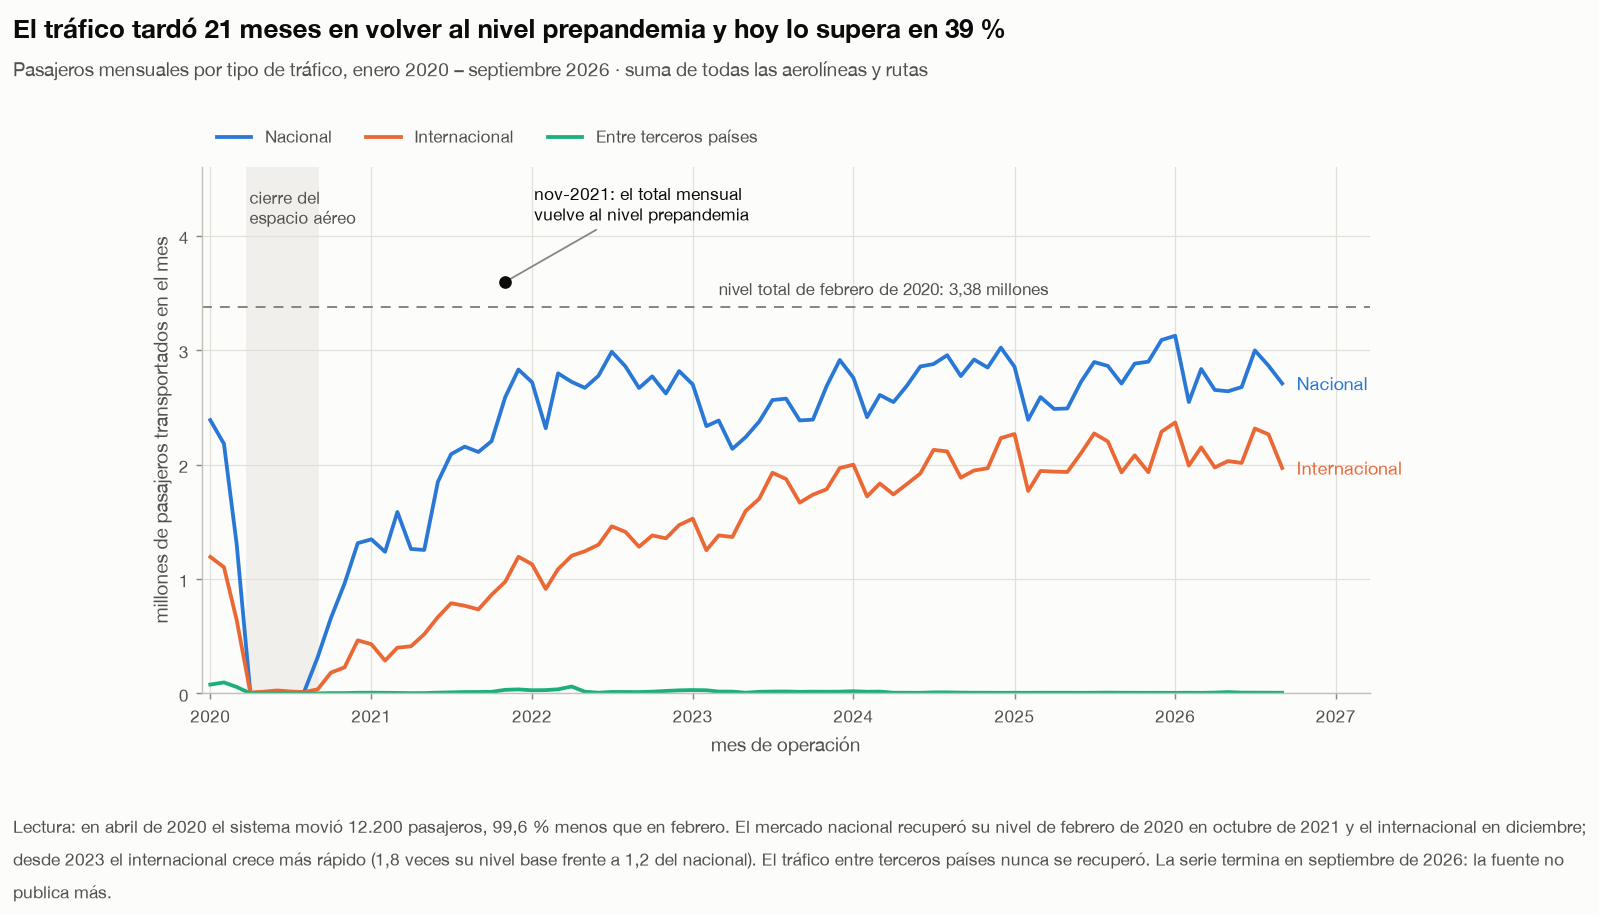

In [20]:
# ===================== FIGURA 6: serie mensual ==============================
s = df.pivot_table(index='fecha', columns='tipo_trafico', values='pasajeros',
                   aggfunc='sum', observed=True) / 1e6
base = s.sum(axis=1).loc['2020-02-01']
recuperacion = s.sum(axis=1)[(s.index > '2020-06-01') & (s.sum(axis=1) >= base)].index[0]
print('Nivel de febrero de 2020  :', round(base, 2), 'millones de pasajeros')
print('Mínimo de la serie        :', s.sum(axis=1).min().round(4), 'millones (abril de 2020)')
print('Primer mes de regreso     :', en_espanol(recuperacion))
for c in s.columns:
    b = s[c].loc['2020-02-01']
    r = s[c][(s.index > '2020-06-01') & (s[c] >= b)]
    print(f'  {c:<24} base {b:.2f} M | recupera: '
          f'{en_espanol(r.index[0]) if len(r) else "no se ha recuperado"} | '
          f'hoy = {s[c].iloc[-1]/b:.2f} veces la base')

fig, ax = plt.subplots(figsize=(11.6, 5.4))
ax.axvspan(pd.Timestamp('2020-03-25'), pd.Timestamp('2020-09-01'), color='#f0efec', zorder=0)
ax.text(pd.Timestamp('2020-03-30'), 4.42, 'cierre del\nespacio aéreo', fontsize=9.3, color=ev.TINTA_2, va='top')
col = {'Nacional': ev.AZUL, 'Internacional': ev.NARANJA, 'Entre terceros paises': ev.AQUA}
nom = {'Nacional': 'Nacional', 'Internacional': 'Internacional',
       'Entre terceros paises': 'Entre terceros países'}
for c in ['Nacional', 'Internacional', 'Entre terceros paises']:
    ax.plot(s.index, s[c], color=col[c], linewidth=2.1, label=nom[c])
for c in ['Nacional', 'Internacional']:
    ax.annotate(nom[c], (s.index[-1], s[c].iloc[-1]), xytext=(8, 0), textcoords='offset points',
                color=col[c], fontsize=10, va='center')
ax.axhline(base, color=ev.TINTA_3, linewidth=1.1, linestyle=(0, (5, 4)))
ax.text(pd.Timestamp('2023-03-01'), base + 0.1,
        f'nivel total de febrero de 2020: {ev.num(base, 2)} millones', fontsize=9.4, color=ev.TINTA_2)
ax.plot([recuperacion], [s.loc[recuperacion].sum()], 'o', color=ev.TINTA, markersize=6, zorder=6)
ax.annotate('nov-2021: el total mensual\nvuelve al nivel prepandemia',
            xy=(recuperacion, s.loc[recuperacion].sum()), xytext=(16, 34),
            textcoords='offset points', fontsize=9.5, color=ev.TINTA,
            arrowprops=dict(arrowstyle='-', color=ev.TINTA_3, linewidth=1))
ax.set_xlim(s.index[0] - pd.Timedelta(days=20), s.index[-1] + pd.Timedelta(days=200))
ax.set_ylim(0, 4.6)
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_ylabel('millones de pasajeros transportados en el mes'); ax.set_xlabel('mes de operación')
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.01), ncols=3)
ev.rotular(fig, 'El tráfico tardó 21 meses en volver al nivel prepandemia y hoy lo supera en 39 %',
           'Pasajeros mensuales por tipo de tráfico, enero 2020 – septiembre 2026 · suma de todas las aerolíneas y rutas',
           'en abril de 2020 el sistema movió 12.200 pasajeros, 99,6 % menos que en febrero. El mercado nacional '
           'recuperó su nivel de febrero de 2020 en octubre de 2021 y el internacional en diciembre; desde 2023 el '
           'internacional crece más rápido (1,8 veces su nivel base frente a 1,2 del nacional). El tráfico entre '
           'terceros países nunca se recuperó. La serie termina en septiembre de 2026: la fuente no publica más.',
           top=0.88, bottom=0.13)
ev.guardar(fig, FIG / 'fig06_serie_mensual.png')
plt.show()

**Por qué una línea.** La pregunta es por la trayectoria de una magnitud continua en 81 meses consecutivos:
es el caso de libro para una línea. Con barras, 81 períodos producirían una empalizada ilegible y el momento
exacto de la recuperación —que es el hallazgo— se perdería entre las barras. Las tres series se dibujan en el
mismo eje, en la misma unidad, para que sean comparables; el nivel de febrero de 2020 va como línea de
referencia horizontal en vez de como una segunda escala.

Índice estacional promedio 2022-2025 (100 = promedio del año):
mes        1     2     3     4     5      6      7      8     9      10     11     12
índice  101.8  85.8  94.4  91.8  94.6  100.6  108.5  106.9  98.1  102.6  102.7  112.3


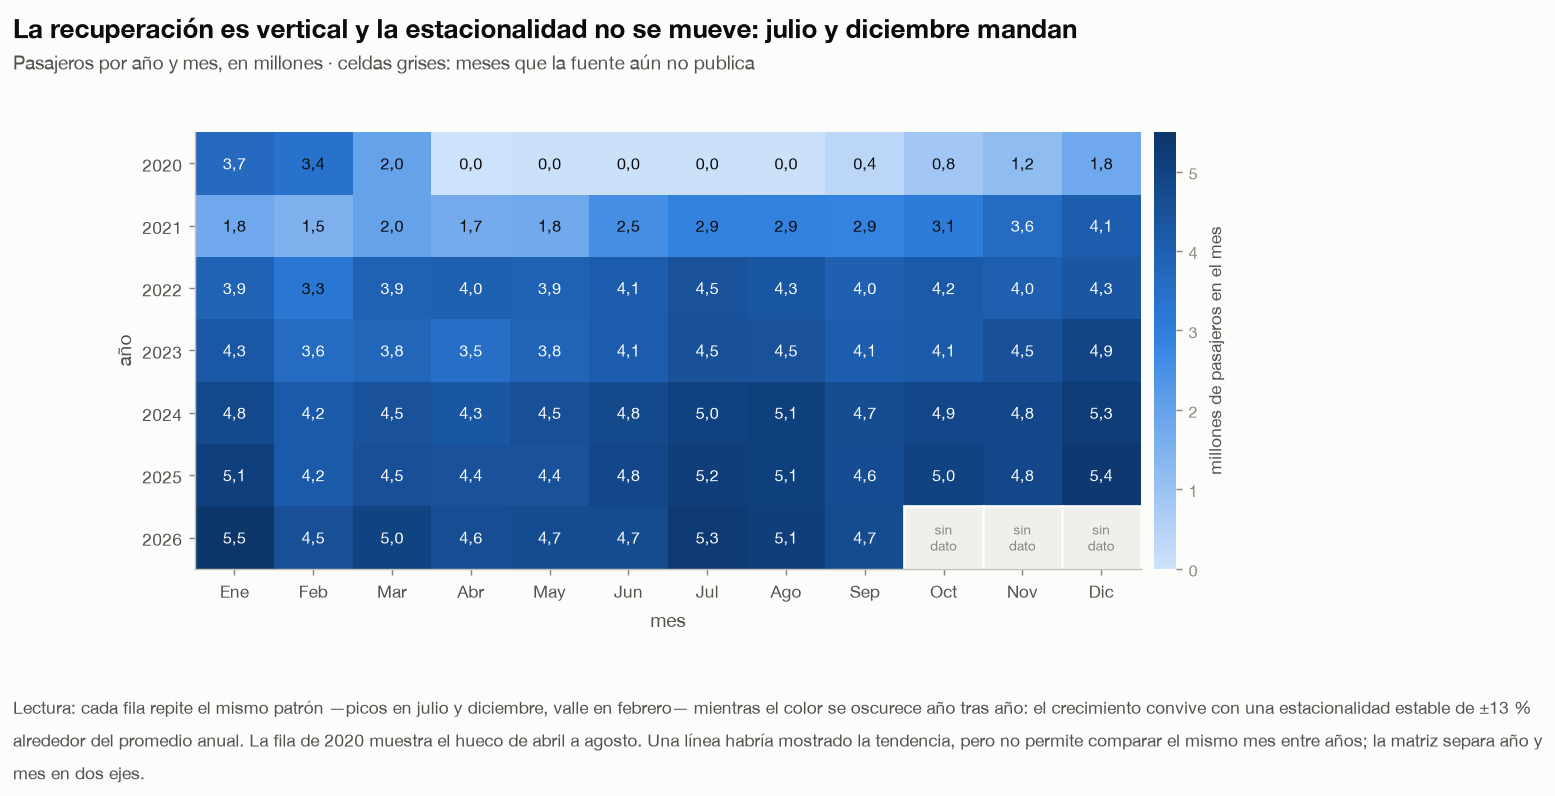

In [21]:
# ===================== FIGURA 7: estacionalidad =============================
piv = df.pivot_table(index='anio', columns='mes', values='pasajeros', aggfunc='sum') / 1e6
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
indice = (100 * piv.loc[2022:2025].div(piv.loc[2022:2025].mean(axis=1), axis=0)).mean()
print('Índice estacional promedio 2022-2025 (100 = promedio del año):')
print(indice.round(1).to_frame('índice').T.to_string())

fig, ax = plt.subplots(figsize=(11.2, 4.6))
im = ax.imshow(piv.values, cmap=ev.SECUENCIAL, aspect='auto', vmin=0, vmax=np.nanmax(piv.values))
ax.set_xticks(range(12)); ax.set_xticklabels(MESES)
ax.set_yticks(range(len(piv.index))); ax.set_yticklabels(piv.index); ax.grid(False)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if np.isnan(v):
            ax.add_patch(plt.Rectangle((j-.5, i-.5), 1, 1, facecolor='#f0efec',
                                       edgecolor=ev.SUPERFICIE, linewidth=1.5))
            ax.text(j, i, 'sin\ndato', ha='center', va='center', fontsize=7.5, color=ev.TINTA_3)
        else:
            ax.text(j, i, ev.num(v, 1), ha='center', va='center', fontsize=9,
                    color='white' if v > np.nanmax(piv.values)*0.62 else ev.TINTA)
ax.set_xlabel('mes'); ax.set_ylabel('año')
cb = fig.colorbar(im, ax=ax, pad=0.012)
cb.set_label('millones de pasajeros en el mes', fontsize=9.5, color=ev.TINTA_2)
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=9, colors=ev.TINTA_3)
ev.rotular(fig, 'La recuperación es vertical y la estacionalidad no se mueve: julio y diciembre mandan',
           'Pasajeros por año y mes, en millones · celdas grises: meses que la fuente aún no publica',
           'cada fila repite el mismo patrón —picos en julio y diciembre, valle en febrero— mientras el color se '
           'oscurece año tras año: el crecimiento convive con una estacionalidad estable de ±13 % alrededor del '
           'promedio anual. La fila de 2020 muestra el hueco de abril a agosto. Una línea habría mostrado la '
           'tendencia, pero no permite comparar el mismo mes entre años; la matriz separa año y mes en dos ejes.',
           top=0.90, bottom=0.17)
ev.guardar(fig, FIG / 'fig07_estacionalidad.png')
plt.show()

## 7. La estructura de la red y del mercado

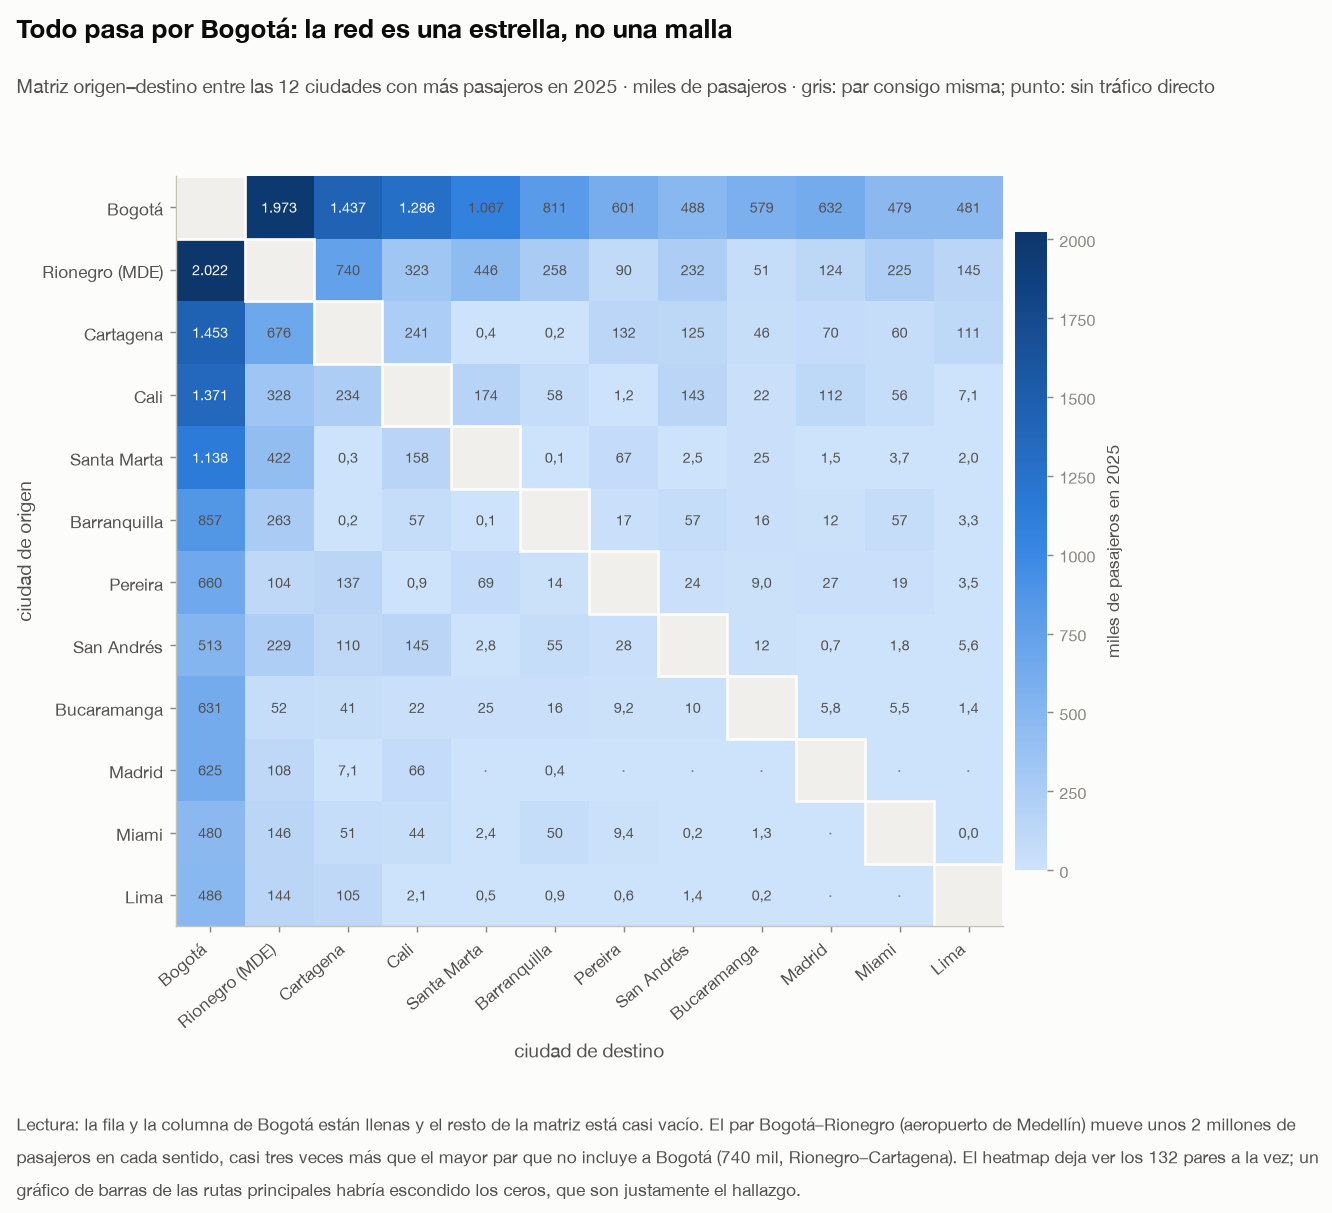

In [22]:
# ================== FIGURA 8: matriz origen-destino =========================
d25 = df[df.anio == 2025]
top = (pd.concat([d25.groupby('ciudad_origen', observed=True).pasajeros.sum(),
                  d25.groupby('ciudad_destino', observed=True).pasajeros.sum()], axis=1)
       .sum(axis=1).sort_values(ascending=False).head(12).index.tolist())
m = (d25[d25.ciudad_origen.isin(top) & d25.ciudad_destino.isin(top)]
     .pivot_table(index='ciudad_origen', columns='ciudad_destino', values='pasajeros',
                  aggfunc='sum', observed=True).reindex(index=top, columns=top).fillna(0) / 1e3)
M = m.to_numpy(dtype=float, copy=True)
np.fill_diagonal(M, np.nan)             # el par de una ciudad consigo misma no es una ruta

corto = {'BOGOTA, D.C.': 'Bogotá', 'RIONEGRO - ANTIOQUIA': 'Rionegro (MDE)',
         'CARTAGENA DE INDIAS': 'Cartagena', 'SANTIAGO DE CALI': 'Cali', 'SANTA MARTA': 'Santa Marta',
         'BARRANQUILLA': 'Barranquilla', 'PEREIRA': 'Pereira', 'SAN ANDRES - ISLA': 'San Andrés',
         'BUCARAMANGA': 'Bucaramanga', 'MADRID': 'Madrid', 'MIAMI': 'Miami', 'LIMA': 'Lima'}
lab = [corto.get(t, t.title()) for t in top]
sin_bogota = m.drop(index='BOGOTA, D.C.', columns='BOGOTA, D.C.').to_numpy().max()

fig, ax = plt.subplots(figsize=(9.8, 7.4))
im = ax.imshow(M, cmap=ev.SECUENCIAL, aspect='auto', vmin=0, vmax=np.nanmax(M))
ax.set_xticks(range(len(top))); ax.set_xticklabels(lab, rotation=40, ha='right')
ax.set_yticks(range(len(top))); ax.set_yticklabels(lab); ax.grid(False)
for i in range(len(top)):
    for j in range(len(top)):
        v = M[i, j]
        if np.isnan(v):
            ax.add_patch(plt.Rectangle((j-.5, i-.5), 1, 1, facecolor='#f0efec',
                                       edgecolor=ev.SUPERFICIE, linewidth=1.5))
        elif v > 0:
            ax.text(j, i, ev.miles(v) if v >= 10 else ev.num(v, 1), ha='center', va='center',
                    fontsize=8, color='white' if v > np.nanmax(M)*0.55 else ev.TINTA_2)
        else:
            ax.text(j, i, '·', ha='center', va='center', fontsize=9, color=ev.TINTA_3)
ax.set_xlabel('ciudad de destino'); ax.set_ylabel('ciudad de origen')
cb = fig.colorbar(im, ax=ax, pad=0.012, shrink=0.85)
cb.set_label('miles de pasajeros en 2025', fontsize=9.5, color=ev.TINTA_2)
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=9, colors=ev.TINTA_3)
ev.rotular(fig, 'Todo pasa por Bogotá: la red es una estrella, no una malla',
           'Matriz origen–destino entre las 12 ciudades con más pasajeros en 2025 · miles de pasajeros · gris: par consigo misma; punto: sin tráfico directo',
           f'la fila y la columna de Bogotá están llenas y el resto de la matriz está casi vacío. El par '
           f'Bogotá–Rionegro (aeropuerto de Medellín) mueve unos 2 millones de pasajeros en cada sentido, casi tres '
           f'veces más que el mayor par que no incluye a Bogotá ({ev.miles(sin_bogota)} mil, Rionegro–Cartagena). '
           f'El heatmap deja ver los 132 pares a la vez; un gráfico de barras de las rutas principales habría '
           f'escondido los ceros, que son justamente el hallazgo.',
           top=0.93, bottom=0.15)
ev.guardar(fig, FIG / 'fig08_matriz_od.png')
plt.show()

Participación de mercado 2025 (%):
empresa
AVIANCA                                           38.4
AIRES                                             17.0
JETSMART COLOMBIA                                  7.7
AEROREPUBLICA                                      6.1
COPA AIRLINES                                      4.9
AVIANCA EXPRESS                                    3.3
EASYFLY S.A                                        2.9
SERVICIO AEREO A TERRITORIOS NACIONALES SATENA     2.6
AEROGAL                                            1.6
AMERICAN AIRLINES                                  1.6

Índice Herfindahl-Hirschman: 1.921 | top 3 = 63.1 % | top 10 = 86.0 %


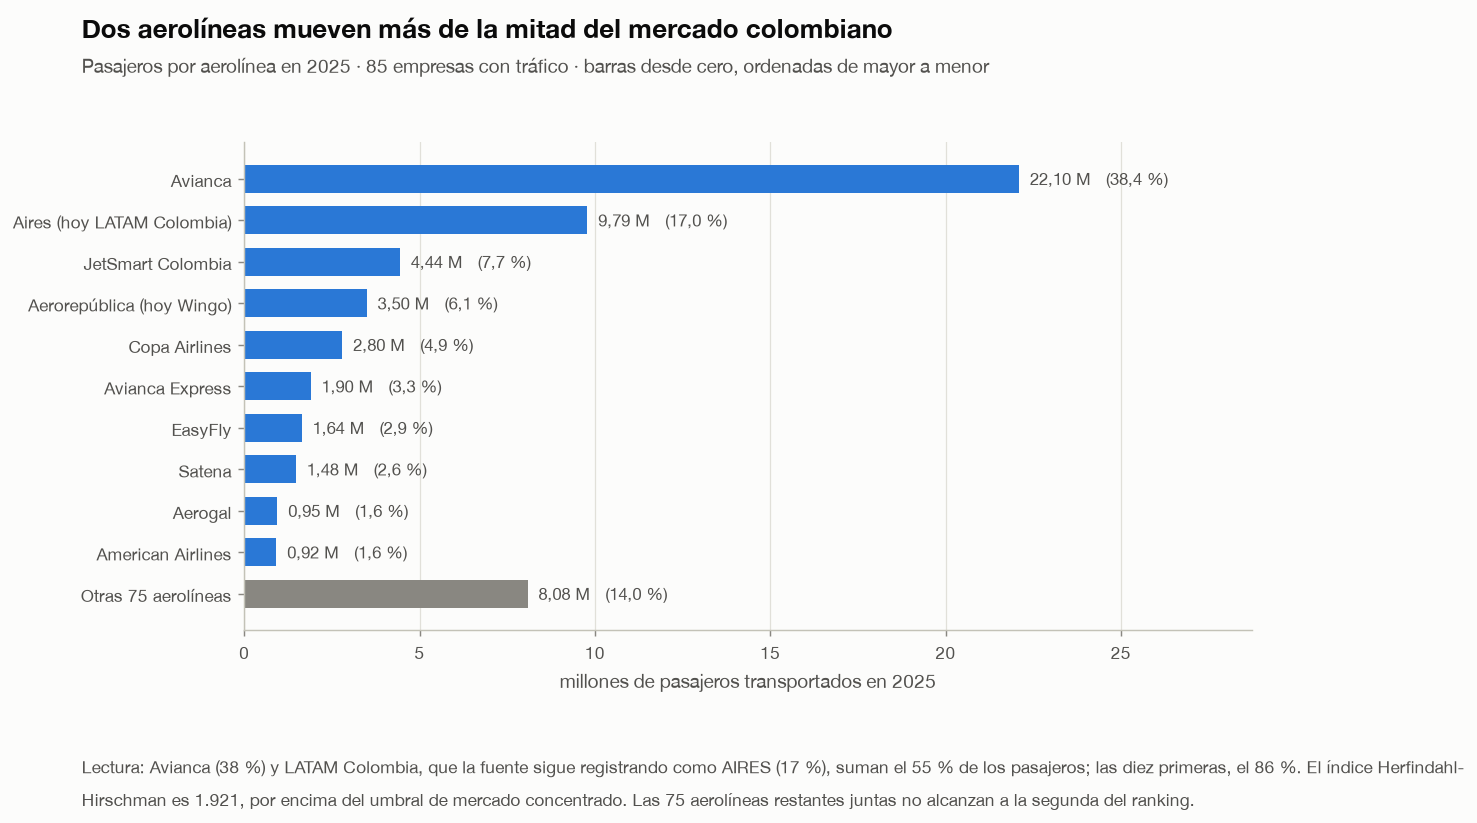

In [23]:
# ===================== FIGURA 9: concentración del mercado ==================
e25 = df[df.anio == 2025].groupby('empresa', observed=True).pasajeros.sum()
e25 = e25[e25 > 0].sort_values(ascending=False) / 1e6
top10 = e25.head(10)
serie = pd.concat([top10, pd.Series({f'Otras {len(e25)-10} aerolíneas': e25.iloc[10:].sum()})])
hhi = ((100 * e25 / e25.sum())**2).sum()
print('Participación de mercado 2025 (%):')
print((100*top10/e25.sum()).round(1).to_string())
print(f'\nÍndice Herfindahl-Hirschman: {hhi:,.0f}'.replace(',', '.'),
      f'| top 3 = {100*top10.head(3).sum()/e25.sum():.1f} % | top 10 = {100*top10.sum()/e25.sum():.1f} %')

nombres = {'SERVICIO AEREO A TERRITORIOS NACIONALES SATENA': 'Satena',
           'AIRES': 'Aires (hoy LATAM Colombia)', 'AEROREPUBLICA': 'Aerorepública (hoy Wingo)',
           'JETSMART COLOMBIA': 'JetSmart Colombia', 'AVIANCA EXPRESS': 'Avianca Express',
           'EASYFLY S.A': 'EasyFly', 'AMERICAN AIRLINES': 'American Airlines',
           'COPA AIRLINES': 'Copa Airlines', 'AEROGAL': 'Aerogal', 'AVIANCA': 'Avianca'}
etiquetas = [nombres.get(i, i if i.startswith('Otras') else i.title()) for i in serie.index]

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(serie))
b = ax.barh(y, serie.values, color=[ev.AZUL]*len(top10) + [ev.TINTA_3], height=0.68)
ax.set_yticks(y); ax.set_yticklabels(etiquetas, fontsize=9.5); ax.invert_yaxis()
ax.bar_label(b, labels=[f'{ev.num(v, 2)} M   ({ev.num(100*v/e25.sum(), 1)} %)' for v in serie.values],
             padding=6, fontsize=9.3, color=ev.TINTA_2)
ax.set_xlim(0, serie.max()*1.3); ax.grid(axis='y', visible=False)
ax.set_xlabel('millones de pasajeros transportados en 2025')
ev.rotular(fig, 'Dos aerolíneas mueven más de la mitad del mercado colombiano',
           f'Pasajeros por aerolínea en 2025 · {len(e25)} empresas con tráfico · barras desde cero, ordenadas de mayor a menor',
           f'Avianca ({100*top10.iloc[0]/e25.sum():.0f} %) y LATAM Colombia, que la fuente sigue registrando como '
           f'AIRES ({100*top10.iloc[1]/e25.sum():.0f} %), suman el {100*top10.head(2).sum()/e25.sum():.0f} % de los '
           f'pasajeros; las diez primeras, el {100*top10.sum()/e25.sum():.0f} %. El índice Herfindahl-Hirschman es '
           f'{ev.miles(hhi)}, por encima del umbral de mercado concentrado. Las {len(e25)-10} aerolíneas restantes '
           f'juntas no alcanzan a la segunda del ranking.',
           top=0.90, bottom=0.15)
ev.guardar(fig, FIG / 'fig09_aerolineas.png')
plt.show()

**Por qué barras ordenadas y no una torta.** Son once categorías: una torta con once porciones es ilegible y
obliga a comparar ángulos. Las barras parten de cero —cualquier otro origen exageraría las diferencias— y van
ordenadas de mayor a menor, que es como se lee un ranking. La cola de 97 aerolíneas se agrupa en una sola
barra gris para no multiplicar categorías sin información.

## 8. Las tres preguntas, respondidas

### Pregunta 1 · ¿Cuánto tardó el tráfico en recuperar su nivel prepandemia, y se recuperaron igual el mercado nacional y el internacional?

**Hallazgo 1.** El sistema pasó de **3,38 millones** de pasajeros en febrero de 2020 a **12.200** en abril
—una caída del **99,6 %**— y necesitó **21 meses** para volver al punto de partida: el primer mes por encima
del nivel de febrero de 2020 fue **noviembre de 2021**. *(Figura 6.)*

**Hallazgo 2.** Los dos mercados no se recuperaron igual ni siguieron igual. El **nacional** volvió a su nivel
base en **octubre de 2021** y hoy está en **1,24 veces** ese nivel; el **internacional** tardó dos meses más
—**diciembre de 2021**— pero hoy está en **1,79 veces**. El internacional pasó de ser un tercio del tráfico a
ser el 42 % del último mes observado. El tráfico **entre terceros países** nunca se recuperó: sigue en el 6 %
de su nivel de febrero de 2020. *(Figura 6.)*

**Hallazgo 3.** El crecimiento no borró la estacionalidad: entre 2022 y 2025, julio (índice 108) y diciembre
(112) están sistemáticamente por encima del promedio anual y febrero (86) por debajo, con la misma forma todos
los años. *(Figura 7.)*

### Pregunta 2 · ¿Cómo se reparte el tráfico entre rutas, aerolíneas y tipos de vuelo?

**Hallazgo 4.** El reparto es extremo en las tres dimensiones. Por **registro**: el 1 % más grande concentra
el **40 %** de los pasajeros y la mediana (18) es 34 veces menor que la media (614). *(Figura 1.)* Por
**aerolínea**: Avianca y LATAM Colombia suman el **55 %** del mercado de 2025, las diez primeras el **86 %**,
y el índice Herfindahl-Hirschman llega a **1.921**, por encima del umbral de 1.800 con que las autoridades de
competencia clasifican un mercado como concentrado. *(Figura 9.)* Por **ruta**: la red es una estrella
centrada en Bogotá; el par Bogotá–Rionegro mueve unos 2 millones de pasajeros en cada sentido y la mayoría de
los pares entre ciudades grandes que no incluyen a Bogotá no tienen vuelo directo. *(Figura 8.)*

**Hallazgo 5.** Lo que parecía un solo sistema son dos negocios que comparten el archivo: el **vuelo regular**
(78,8 % de los registros, **98,4 %** de los pasajeros, mediana de 33 por registro) y el **taxi aéreo** (17,8 %
de los registros, **0,6 %** de los pasajeros, mediana de 5). Y no se mezclan: el taxi aéreo es **96 %**
nacional y el vuelo regular **82 %** internacional, con una V de Cramér de **0,47**. *(Figuras 2 y 5.)*

### Pregunta 3 · ¿Pasajeros y carga son el mismo negocio?

**Hallazgo 6.** No lo son. Donde conviven, se acompañan (ρ de Spearman = **0,76** entre registros con
pasajeros y carga mayores que cero), pero la pendiente ajustada sobre los logaritmos es **0,63**: duplicar los
pasajeros multiplica la carga por 1,5, no por 2. Y al agregar por ruta y mes la correlación cae a **0,24**.
*(Figuras 3 y 4.)*

**Hallazgo 7.** La razón es que la carga de verdad vuela sola: **31.592 registros** (6,5 % de los activos) no
llevan un solo pasajero y mueven el **78 % de las toneladas** del período. El vínculo que sí existe es
sobre todo internacional (ρ = 0,88) y mucho más débil en el mercado nacional (ρ = 0,62), donde el avión de
pasajeros lleva carga casi como un extra. *(Figura 4.)*

## 9. Limitaciones del análisis

**Cómo se recogieron los datos y a quién representan.** No es una muestra: es el registro administrativo que
las aerolíneas reportan a la Aeronáutica Civil para operar. Cubre, por diseño, únicamente la **aviación
comercial** con permiso de operación: quedan fuera la aviación militar, la privada no comercial, la de
instrucción y cualquier operación no reportada. La unidad de observación tampoco es el vuelo ni el pasajero,
sino el **agregado mensual por aerolínea, ruta, tipo de tráfico y tipo de vuelo**. De ahí se siguen dos
límites: no se puede decir nada sobre frecuencias, ocupación ni tarifas, y un "registro" no es comparable
entre aerolíneas grandes y pequeñas.

**Qué efecto tuvieron los faltantes y las decisiones de limpieza.** Los faltantes son irrelevantes en volumen
(52 celdas, 0,01 %) y la imputación a cero de 41 de ellos solo puede haber subestimado el total en unos pocos
cientos de pasajeros. Las decisiones que sí pesan son otras dos: (a) **conservar los valores extremos**, que
determina todos los agregados —si se hubieran eliminado como "atípicos", el total del período se reduciría en
más de un tercio—; y (b) **mantener las 12.340 filas sin movimiento** con una bandera en lugar de borrarlas,
que cambia los conteos de registros pero no los de pasajeros. La normalización de tildes y nombres corrigió
conteos por categoría, no magnitudes.

**Por qué no hay causalidad aquí.** Las asociaciones encontradas son descripciones, no explicaciones. Que las
rutas con más aerolíneas tengan más pasajeros (ρ = 0,58) no dice que abrir competencia genere demanda: lo más
plausible es lo contrario, que las aerolíneas entren donde ya hay demanda. Que el tráfico internacional crezca
más rápido que el nacional coincide con hechos que el conjunto no contiene —tipo de cambio, entrada de
aerolíneas de bajo costo, la quiebra de Viva Air en 2023, la reestructuración de Avianca— y cualquiera de
ellos puede estar detrás del patrón. Con datos observacionales agregados y sin grupo de comparación, lo único
defendible es describir la trayectoria.

**El límite más incómodo: no hay línea base real.** La serie empieza en enero de 2020, así que "nivel
prepandemia" significa aquí *febrero de 2020*, un mes puntual que además ya incluía una caída inicial. Sin
2018–2019 no se puede saber si ese mes era representativo ni cuánto habría crecido el tráfico sin la pandemia.

**Qué haría falta para sostener estas conclusiones.** (1) La serie 2015–2019 del mismo reporte, para tener una
base y una tendencia contrafactual. (2) Datos de **oferta**: sillas ofrecidas y número de operaciones, que
permitirían calcular factor de ocupación y distinguir si el crecimiento viene de más vuelos o de aviones más
llenos. (3) El diccionario oficial de las categorías: los códigos de tipo de vuelo y de tipo de tráfico se
interpretaron a partir de la evidencia del propio conjunto (sección 10), no de documentación. (4) Tarifas o
ingresos, para pasar de volumen a mercado.

## 10. Problemas técnicos que enfrenté y cómo los resolví

**1. El conjunto no venía con diccionario de datos.** Las columnas `Tráfico (N/I)` y `Tipo Vuelo` traen
códigos de una letra (`N`, `I`, `E` y `R`, `T`, `C`, `A`) sin documentación en el portal. Los deduje con
pandas, contrastando cada código con el resto de las columnas: las filas con `E` tienen país de origen y
destino distintos de Colombia en el **100 %** de los casos (de ahí "entre terceros países"); las filas con `T`
pertenecen a operadores pequeños y tienen una mediana de 4 pasajeros (taxi aéreo), mientras que las `R` son de
Avianca, Copa o American con medianas de decenas o cientos (vuelo regular). La interpretación queda declarada
como supuesto en las limitaciones.

**2. El primer intento de descarga se quedó corto.** El API de Socrata devuelve por defecto **1.000 filas**,
así que la primera descarga parecía un conjunto diminuto y perfectamente limpio. Al revisar el conteo real
(`$select=count(*)` → 501.819) quedó claro el problema. La solución fue usar el *endpoint* de exportación
completa (`/api/views/{id}/rows.csv?accessType=DOWNLOAD`) con `curl --compressed`, que trae las 501.819 filas
en un archivo de 61 MB.

**3. La normalización de nombres de columna rompió el código.** Mi función `a_snake` quita las tildes antes de
reemplazar caracteres, así que `Año` no se convirtió en `a_o` como esperaba sino en `ano`, y el renombrado
posterior falló con un `KeyError`. Lo detecté al ejecutar y lo corregí mapeando el nombre real; de paso quedó
clara la lección de imprimir `list(df.columns)` justo después de renombrar.

**4. Los primeros gráficos eran ilegibles o engañosos.** Tres casos concretos:
   - El histograma de pasajeros en **escala lineal** mostraba una sola barra pegada al eje: todo el conjunto
     cabía en el primer bin. Pasé a escala logarítmica, y ahí aparecieron las dos poblaciones.
   - La **dispersión** de pasajeros contra carga era una mancha negra de 130 mil puntos sin estructura
     visible. La reemplacé por un hexbin, y como la celda más densa tiene 1.500 veces más registros que las
     del borde, tuve que pasar también el **color a escala logarítmica**: con escala lineal el gráfico
     completo salía del tono más claro y parecía vacío.
   - La primera versión del diagnóstico era una **matriz de faltantes** sobre una muestra de 1.200 filas.
     Como los faltantes son 52 de 501.819, la figura salía completamente uniforme y no mostraba nada. La
     cambié por el gráfico de grafías duplicadas, que sí muestra el problema real del archivo.

**5. Los títulos se montaban sobre los gráficos.** Al poner título, subtítulo y leyenda con `fig.text`, el
texto se superponía con los ejes y la nota al pie se salía del lienzo. Resolví escribiendo una función
`rotular()` en `scripts/estilo_viz.py` que reserva márgenes con `subplots_adjust` y parte la nota en líneas
según el ancho real de la figura.

**6. El año 2026 está incompleto y casi arruina las comparaciones.** Mi primera tabla anual mostraba 2026 muy
por debajo de 2025 y parecía una caída del tráfico. En realidad la fuente solo llega a septiembre. Excluí 2026
de toda comparación anual y, cuando hay que compararlo, uso el acumulado enero–septiembre contra el mismo
período del año anterior (44,2 millones en 2026 frente a 42,4 millones en 2025: +4,2 %).

## 11. Declaración de uso de inteligencia artificial

Declaro el uso de un asistente de inteligencia artificial (**Claude**, de Anthropic) durante la realización de
este trabajo, en los siguientes puntos:

| Para qué se usó | Cómo |
|---|---|
| Búsqueda del conjunto de datos | Exploración del catálogo de `datos.gov.co` y verificación de los criterios exigidos (licencia, tamaño, tipos de variable, imperfecciones). |
| Código de limpieza y análisis | Redacción y depuración del código de `pandas`, `seaborn` y `scipy` de este cuaderno. Todo el código fue ejecutado y verificado por mí: las cifras del informe salen de las celdas que aquí se ven corriendo. |
| Diseño de las figuras | Definición de la paleta, el estilo de `matplotlib` y la elección del tipo de gráfico para cada pregunta. |
| Redacción | Apoyo en la redacción de las lecturas de las figuras y de las secciones de hallazgos y limitaciones. |

**No** se usó inteligencia artificial para generar, imputar ni modificar datos: todas las cifras provienen del
archivo descargado de `datos.gov.co` y de las transformaciones documentadas en la sección 3. Las decisiones de
limpieza, las preguntas de investigación y la interpretación de los resultados son mías, y cada afirmación del
informe está respaldada por una celda ejecutada o una figura de este cuaderno.

## 12. Cómo reproducir este análisis desde cero

```bash
pip install -r requirements.txt
python scripts/01_descargar_datos.py      # descarga las 501.819 filas desde datos.gov.co
jupyter lab notebooks/analisis_exploratorio.ipynb
```

El cuaderno se ejecuta de principio a fin sin intervención: lee el CSV crudo, aplica la limpieza, guarda el
conjunto depurado en `datos/procesados/` y regenera las nueve figuras en `figuras/`.

**Estructura del proyecto**

```
EDA_trafico_aereo_colombia/
├── datos/crudos/        archivo descargado sin modificar
├── datos/procesados/    conjunto limpio (parquet)
├── scripts/             descarga, estilo visual y construcción del cuaderno
├── notebooks/           este cuaderno, ejecutado, y su versión HTML
├── figuras/             las nueve figuras en PNG a 200 ppp
└── README.md
```

**Fuente de los datos.** Aeronáutica Civil de Colombia, *Transporte Aéreo Comercial – Tráfico Origen‑Destino
(Colombia)*, conjunto `gb6w-ynu4` del portal `datos.gov.co`, descargado el 23 de noviembre de 2026.
Licencia Creative Commons Attribution Share-Alike 4.0 International.